# Notebook Instructions

This notebook documents the complete development process of the diabetes risk screening models, including data preparation, exploratory data analysis (EDA), model training, optimization, evaluation, and interpretation.

### Execution Options

Users can choose between two execution approaches depending on their needs:

**Option 1 — Full Optimization (Optional)**

- Navigate to **Model Optimization Full Optuna Version**.
- Uncomment and execute the relevant code cells to reproduce the full hyperparameter optimization process, including global and capacity-specific XGBoost models.
- This process is computationally expensive and may take considerable time.
- Save the trained models and optimization results for future use.


**Option 2 — Skip Optimization (Recommended)**

- Run the environment setup, data acquisition, EDA, and data preparation sections.
- Skip **Model Optimization Full Optuna Version**.
- Download the saved models and Optuna results from the [GitHub repository for model shortcuts](https://github.com/hung0302/Data_Mining-Group9-Diabetes-Risk-Screening-Optimization/tree/main/model_optimization_shortcut_files).
- Upload all required `.pkl` and `.json` files to the Colab working directory.
- Navigate to **Model Optimization Shortcuts** and execute the loading cell.
- Continue with **Final Evaluation**, **Feature Importance**, and **Calibration**.


### Important Notes

- **The Shortcuts option is recommended** for reviewing the results, reproducing evaluation outputs, or exploring model interpretations without repeating computationally intensive optimization.
- The Shortcuts option requires the saved `.pkl` files and `.json` metadata files. Ensure that `SAVE_DIR` points to the correct directory.
- The Full Optimization section is commented out by default and must be uncommented before execution.
- Follow the notebook sections in order to ensure that all required variables and data splits are initialized.
- Both approaches are intended to use the same saved model configurations and evaluation methodology.

#Environment & Reproducibility

**Noted about Capacity levels**

There is no universal hospital screening capacity, so the selected values represent a range of resource constraints observed in healthcare risk-stratification research and real-world implementations.

\[
K in \{0.5\%, 1\%, 2.5\%, 5\%, 10\%, 20\%\}
\]

- **0.5%**: extreme resource constraint; used in PRISM high-risk stratification.
- **1%**: very high-risk targeting; used in VHA STORM and the Highest-k diabetes study.
- **2.5%**: intensive targeted outreach; used in real-world suicide-risk outreach.
- **5%**: common high-risk case-management threshold and a key Highest-k benchmark.
- **10%**: moderate capacity and also evaluated in the Highest-k diabetes study.
- **20%**: high-capacity scenario; supported by recent diabetes case-management research.

The **1%, 5%, and 10%** levels allow direct comparison with the published Highest-k Loss diabetes benchmark.

**Sources:** Snooks et al. (2019); Chinman et al. (2019); Yarborough et al. (2022); Yang et al. (2023); Lee et al. (2026).

---

**Noted about cross-validation**

A **5-fold Stratified K-Fold cross-validation** strategy is used to preserve the diabetes class proportion across folds while providing a stable estimate of model performance.

Five folds offer a practical balance between evaluation reliability and computational cost, especially because boosting models will later be tuned repeatedly with Optuna.

The separate test set remains **locked** and is used only for final evaluation.

In [ ]:
# 0. Environment & Reproducibility

!pip -q install optuna xgboost lightgbm catboost ucimlrepo shap

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import optuna
import shap

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

TARGET = "Diabetes_binary"
CAPACITIES = [0.005, 0.01, 0.025, 0.05, 0.10, 0.20]

N_SPLITS = 5
TEST_SIZE = 0.20

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

print("Environment ready")
print(f"Random seed: {SEED}")
print(f"Capacities: {[f'{k:.1%}' for k in CAPACITIES]}")

Environment ready
Random seed: 42
Capacities: ['0.5%', '1.0%', '2.5%', '5.0%', '10.0%', '20.0%']
Environment ready
Random seed: 42
Capacities: ['0.5%', '1.0%', '2.5%', '5.0%', '10.0%', '20.0%']


#Import Data

This study uses the **Diabetes Health Indicators** dataset from the UCI Machine Learning Repository, derived from the **2015 Behavioral Risk Factor Surveillance System (BRFSS)**.

- **Observations:** 253,680 individuals
- **Predictors:** 21 variables
- **Target:** Binary diabetes status (`Diabetes_binary`)
- **Feature types:** Health conditions, health behaviors, demographic characteristics, socioeconomic factors, and healthcare access indicators

Most predictors are based on survey responses rather than laboratory measurements, making the dataset suitable for exploring **low-cost diabetes risk screening before more expensive clinical testing**.

The target is imbalanced, with approximately **86% non-diabetic and 14% diabetic cases**, so accuracy alone is not sufficient for model evaluation. This motivates the use of ranking-based metrics such as **PR-AUC** and **Precision@K**.

In [ ]:
# 2. Data Acquisition & Basic Validation

import pandas as pd
from ucimlrepo import fetch_ucirepo

# Primary source: UCI Machine Learning Repository
# Fallback source: Group 9 GitHub repository

github_url = (
    "https://raw.githubusercontent.com/"
    "hung0302/Data_Mining-Group9-Diabetes-Risk-Screening-Optimization/"
    "main/diabetes_binary_health_indicators_BRFSS2015.csv"
)

try:
    print("Attempting to load dataset from UCI...")

    dataset = fetch_ucirepo(id=891)

    X = dataset.data.features.copy()
    y = dataset.data.targets.copy()

    df = pd.concat([X, y], axis=1)

    print("Successfully loaded from UCI Repository.")

except Exception as e:
    print(f"UCI loading failed: {e}")
    print("Switching to GitHub backup...")

    df = pd.read_csv(github_url)

    X = df.drop(columns=["Diabetes_binary"]).copy()
    y = df[["Diabetes_binary"]].copy()

    print("Successfully loaded from GitHub backup.")

# Verify dataset integrity
assert df.shape == (253680, 22), "Unexpected dataset shape!"
assert X.shape[1] == 21, "Unexpected number of features!"
assert y.iloc[:, 0].sum() == 35346, "Unexpected target distribution!"

# Basic Validation
print(f"\nDataset shape : {df.shape}")
print(f"Features      : {X.shape[1]}")
print(f"Target        : {y.columns[0]}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicates    : {df.duplicated().sum()}")

display(df.head())

print("\nTarget distribution:")
display(
    y.iloc[:, 0]
    .value_counts()
    .rename_axis("Class")
    .to_frame("Count")
    .assign(Percentage=lambda x: x["Count"] / len(y) * 100)
)

Dataset shape : (253680, 22)
Features      : 21
Target        : Diabetes_binary
Missing values: 0
Duplicates    : 24206
Dataset shape : (253680, 22)
Features      : 21
Target        : Diabetes_binary
Missing values: 0
Duplicates    : 24206


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,0,1,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,0,0,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,0,1,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,0,1,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,0,1,0,2,3,0,0,0,11,5,4,0



Target distribution:


,Count,Percentage
Class,,
0,218334,86.0667
1,35346,13.9333


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,0,1,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,0,0,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,0,1,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,0,1,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,0,1,0,2,3,0,0,0,11,5,4,0



Target distribution:


,Count,Percentage
Class,,
0,218334,86.0667
1,35346,13.9333


In [ ]:
# If above code meet errors
# # 2. Data Acquisition & Basic Validation

# import pandas as pd
# from ucimlrepo import fetch_ucirepo

# try:
#     print("Attempting to fetch dataset from UCI ML Repository...")
#     # UCI Diabetes Health Indicators dataset
#     dataset = fetch_ucirepo(id=891)
#     X = dataset.data.features.copy()
#     y = dataset.data.targets.copy()
#     df = pd.concat([X, y], axis=1)
# except Exception as e:
#     print(f"UCI connection failed: {e}")
#     print("Falling back to public mirror dataset download...")
#     # Use a direct public CSV link of the BRFSS 2015 Diabetes indicators dataset
#     csv_url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/diabetes.csv"
#     # However, since the BRFSS 2015 has 22 specific columns, let's load from a replica or direct source if available.
#     # Let's use a highly available direct mirror for the exact UCI id 891 (diabetes_binary_health_indicators_BRFSS2015.csv)
#     mirror_url = "https://media.githubusercontent.com/media/joshua-unm/diabetes-prediction/main/diabetes_binary_health_indicators_BRFSS2015.csv"
#     df = pd.read_csv(mirror_url)
#     X = df.drop(columns=["Diabetes_binary"]).copy()
#     y = df[["Diabetes_binary"]].copy()

# print(f"Dataset shape : {df.shape}")
# print(f"Features      : {X.shape[1]}")
# print(f"Target        : {y.columns[0]}")
# print(f"Missing values: {df.isna().sum().sum()}")
# print(f"Duplicates    : {df.duplicated().sum()}")

# display(df.head())

# print("\nTarget distribution:")
# display(
#     y.iloc[:, 0]
#     .value_counts()
#     .rename_axis("Class")
#     .to_frame("Count")
#     .assign(Percentage=lambda x: x["Count"] / len(y) * 100)
# )

#EDA

##Data Quality

**Data quality**

The dataset contains **253,680 observations and 22 variables**, including 21 predictors and the binary diabetes target. No missing values are present.

A total of **24,206 rows (9.54%)** have identical values across all available variables. These should **not be treated as confirmed duplicate patients**, because the public BRFSS-derived dataset does not retain a unique patient/respondent identifier. Since the identifier has been removed, different respondents can legitimately have the same combination of survey responses.

Therefore, these repeated rows are retained rather than automatically deleted. Removing them could incorrectly discard valid respondents and alter the observed population distribution.

In [ ]:
quality_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
    "min": df.min(),
    "max": df.max()
})

display(quality_summary)

print(f"Observations   : {len(df):,}")
print(f"Variables      : {df.shape[1]}")
print(f"Missing cells  : {df.isna().sum().sum():,}")
print(f"Duplicate rows : {df.duplicated().sum():,}")
print(f"Duplicate rate : {df.duplicated().mean() * 100:.2f}%")

,dtype,missing,missing_pct,unique_values,min,max
HighBP,int64,0,0.0000,2,0,1
HighChol,int64,0,0.0000,2,0,1
CholCheck,int64,0,0.0000,2,0,1
BMI,int64,0,0.0000,84,12,98
Smoker,int64,0,0.0000,2,0,1
Stroke,int64,0,0.0000,2,0,1
HeartDiseaseorAttack,int64,0,0.0000,2,0,1
PhysActivity,int64,0,0.0000,2,0,1
Fruits,int64,0,0.0000,2,0,1
Veggies,int64,0,0.0000,2,0,1


Observations   : 253,680
Variables      : 22
Missing cells  : 0
Duplicate rows : 24,206
Duplicate rate : 9.54%


##Statiscal Indicator

In [ ]:
# Statistical indicators for EDA

numeric_vars = [
    "BMI",
    "MentHlth",
    "PhysHlth",
    "GenHlth",
    "Age",
    "Education",
    "Income"
]

stats_table = (
    df[numeric_vars]
    .describe()
    .T
    .rename(columns={
        "count": "N",
        "mean": "Mean",
        "std": "Std",
        "min": "Min",
        "25%": "Q1",
        "50%": "Median",
        "75%": "Q3",
        "max": "Max"
    })
)

stats_table = stats_table[
    ["N", "Mean", "Std", "Min", "Q1", "Median", "Q3", "Max"]
]

print("STATISTICAL INDICATORS")
display(stats_table.round(2))

print("\nDATASET OVERVIEW")
print(f"Observations: {len(df):,}")
print(f"Variables: {df.shape[1]}")
print(f"Missing values: {df.isna().sum().sum():,}")
print(f"Identical rows: {df.duplicated().sum():,}")
print(f"Identical row rate: {df.duplicated().mean()*100:.2f}%")

print("\nBINARY VARIABLE PREVALENCE (%)")

binary_vars = [
    "HighBP", "HighChol", "CholCheck", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]

binary_summary = pd.DataFrame({
    "Variable": binary_vars,
    "Prevalence_1_pct": [
        df[col].mean() * 100 for col in binary_vars
    ]
})

display(binary_summary.round(2))

STATISTICAL INDICATORS
STATISTICAL INDICATORS


,N,Mean,Std,Min,Q1,Median,Q3,Max
BMI,253680.0000,28.3800,6.6100,12.0000,24.0000,27.0000,31.0000,98.0000
MentHlth,253680.0000,3.1800,7.4100,0.0000,0.0000,0.0000,2.0000,30.0000
PhysHlth,253680.0000,4.2400,8.7200,0.0000,0.0000,0.0000,3.0000,30.0000
GenHlth,253680.0000,2.5100,1.0700,1.0000,2.0000,2.0000,3.0000,5.0000
Age,253680.0000,8.0300,3.0500,1.0000,6.0000,8.0000,10.0000,13.0000
Education,253680.0000,5.0500,0.9900,1.0000,4.0000,5.0000,6.0000,6.0000
Income,253680.0000,6.0500,2.0700,1.0000,5.0000,7.0000,8.0000,8.0000


,N,Mean,Std,Min,Q1,Median,Q3,Max
BMI,253680.0000,28.3800,6.6100,12.0000,24.0000,27.0000,31.0000,98.0000
MentHlth,253680.0000,3.1800,7.4100,0.0000,0.0000,0.0000,2.0000,30.0000
PhysHlth,253680.0000,4.2400,8.7200,0.0000,0.0000,0.0000,3.0000,30.0000
GenHlth,253680.0000,2.5100,1.0700,1.0000,2.0000,2.0000,3.0000,5.0000
Age,253680.0000,8.0300,3.0500,1.0000,6.0000,8.0000,10.0000,13.0000
Education,253680.0000,5.0500,0.9900,1.0000,4.0000,5.0000,6.0000,6.0000
Income,253680.0000,6.0500,2.0700,1.0000,5.0000,7.0000,8.0000,8.0000



DATASET OVERVIEW
Observations: 253,680
Variables: 22
Missing values: 0
Identical rows: 24,206
Identical row rate: 9.54%

BINARY VARIABLE PREVALENCE (%)

DATASET OVERVIEW
Observations: 253,680
Variables: 22
Missing values: 0
Identical rows: 24,206
Identical row rate: 9.54%

BINARY VARIABLE PREVALENCE (%)


,Variable,Prevalence_1_pct
0,HighBP,42.9000
1,HighChol,42.4100
2,CholCheck,96.2700
3,Smoker,44.3200
4,Stroke,4.0600
5,HeartDiseaseorAttack,9.4200
6,PhysActivity,75.6500
7,Fruits,63.4300
8,Veggies,81.1400
9,HvyAlcoholConsump,5.6200


,Variable,Prevalence_1_pct
0,HighBP,42.9000
1,HighChol,42.4100
2,CholCheck,96.2700
3,Smoker,44.3200
4,Stroke,4.0600
5,HeartDiseaseorAttack,9.4200
6,PhysActivity,75.6500
7,Fruits,63.4300
8,Veggies,81.1400
9,HvyAlcoholConsump,5.6200


##Target distribution

**Target distribution**

The target variable is clearly imbalanced. Among **253,680 observations**, **218,334 (86.07%)** are non-diabetic, while **35,346 (13.93%)** are diabetic.

This class imbalance means that **accuracy alone would be insufficient for model evaluation**, since a model could achieve high accuracy by favoring the majority non-diabetic class.

The imbalance will therefore be taken into account when selecting evaluation metrics and designing the modeling strategy.

,Count,Percentage
Class,,
0,218334,86.0700
1,35346,13.9300


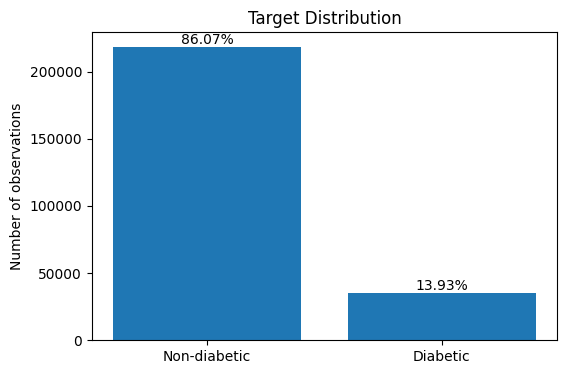

In [ ]:
target_counts = (
    df["Diabetes_binary"]
    .value_counts()
    .sort_index()
    .rename_axis("Class")
    .to_frame("Count")
)

target_counts["Percentage"] = (
    target_counts["Count"] / len(df) * 100
).round(2)

display(target_counts)

plt.figure(figsize=(6, 4))
bars = plt.bar(
    ["Non-diabetic", "Diabetic"],
    target_counts["Count"]
)

plt.title("Target Distribution")
plt.ylabel("Number of observations")

for bar, pct in zip(bars, target_counts["Percentage"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{pct:.2f}%",
        ha="center",
        va="bottom"
    )

plt.show()

##Variable distribution

**Binary feature distributions**

Several binary predictors are strongly imbalanced. Variables such as **Stroke, HeartDiseaseorAttack, HvyAlcoholConsump, NoDocbcCost, and DiffWalk** have relatively few positive cases, while **CholCheck, AnyHealthcare, PhysActivity, and Veggies** are dominated by positive responses.

In contrast, **HighBP, HighChol, Smoker, Fruits, and Sex** show more balanced distributions.

These patterns suggest that some binary variables may have limited standalone separating power because one category dominates the sample. However, they are retained for modeling because rare conditions may still provide useful predictive information when combined with other health and demographic factors.

In [ ]:
binary_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]

ordinal_features = [
    "GenHlth", "Age", "Education", "Income"
]

continuous_features = [
    "BMI", "MentHlth", "PhysHlth"
]

feature_structure = pd.DataFrame({
    "Feature": binary_features + ordinal_features + continuous_features,
    "Type": (
        ["Binary"] * len(binary_features)
        + ["Ordinal"] * len(ordinal_features)
        + ["Continuous"] * len(continuous_features)
    )
})

display(feature_structure)

print(f"Binary features     : {len(binary_features)}")
print(f"Ordinal features    : {len(ordinal_features)}")
print(f"Continuous features : {len(continuous_features)}")
print(f"Total predictors    : {len(feature_structure)}")

,Feature,Type
0,HighBP,Binary
1,HighChol,Binary
2,CholCheck,Binary
3,Smoker,Binary
4,Stroke,Binary
5,HeartDiseaseorAttack,Binary
6,PhysActivity,Binary
7,Fruits,Binary
8,Veggies,Binary
9,HvyAlcoholConsump,Binary


Binary features     : 14
Ordinal features    : 4
Continuous features : 3
Total predictors    : 21


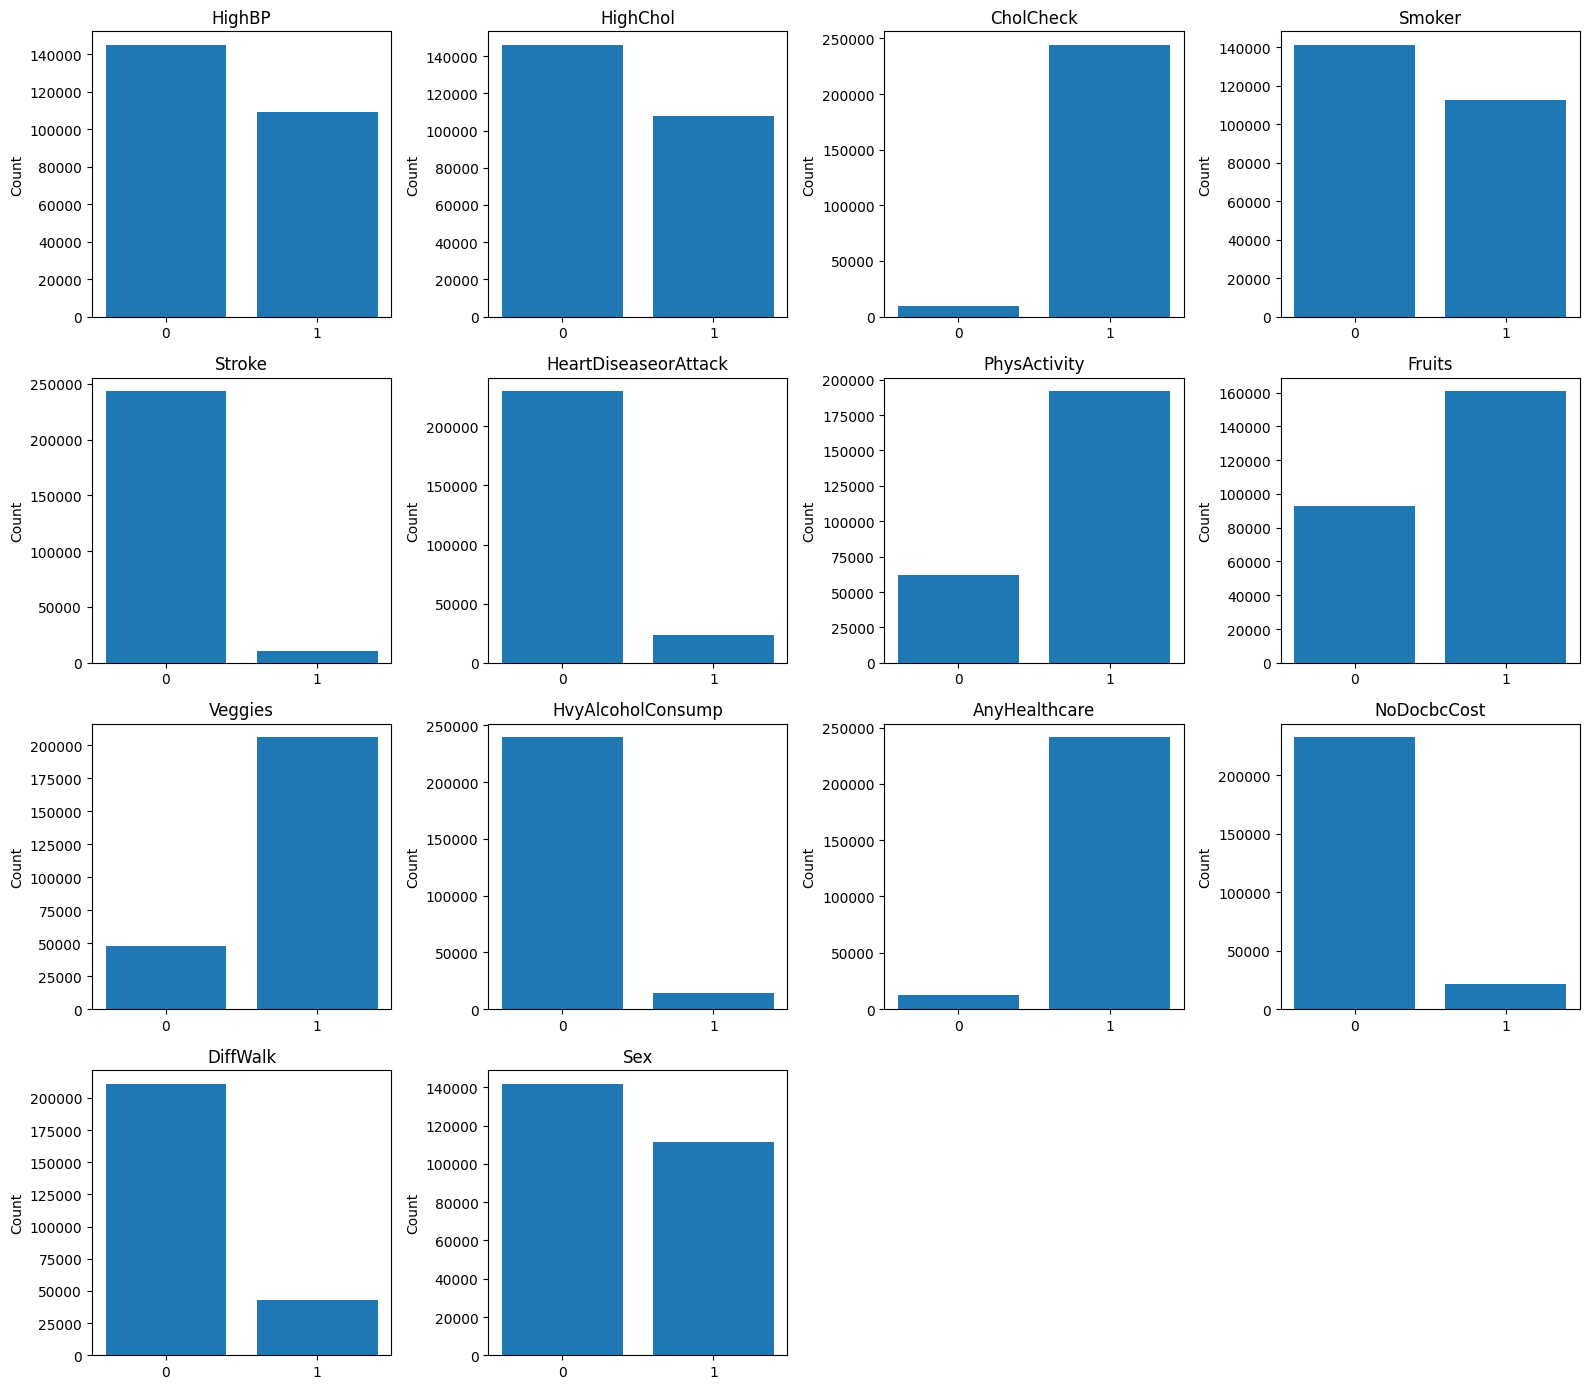

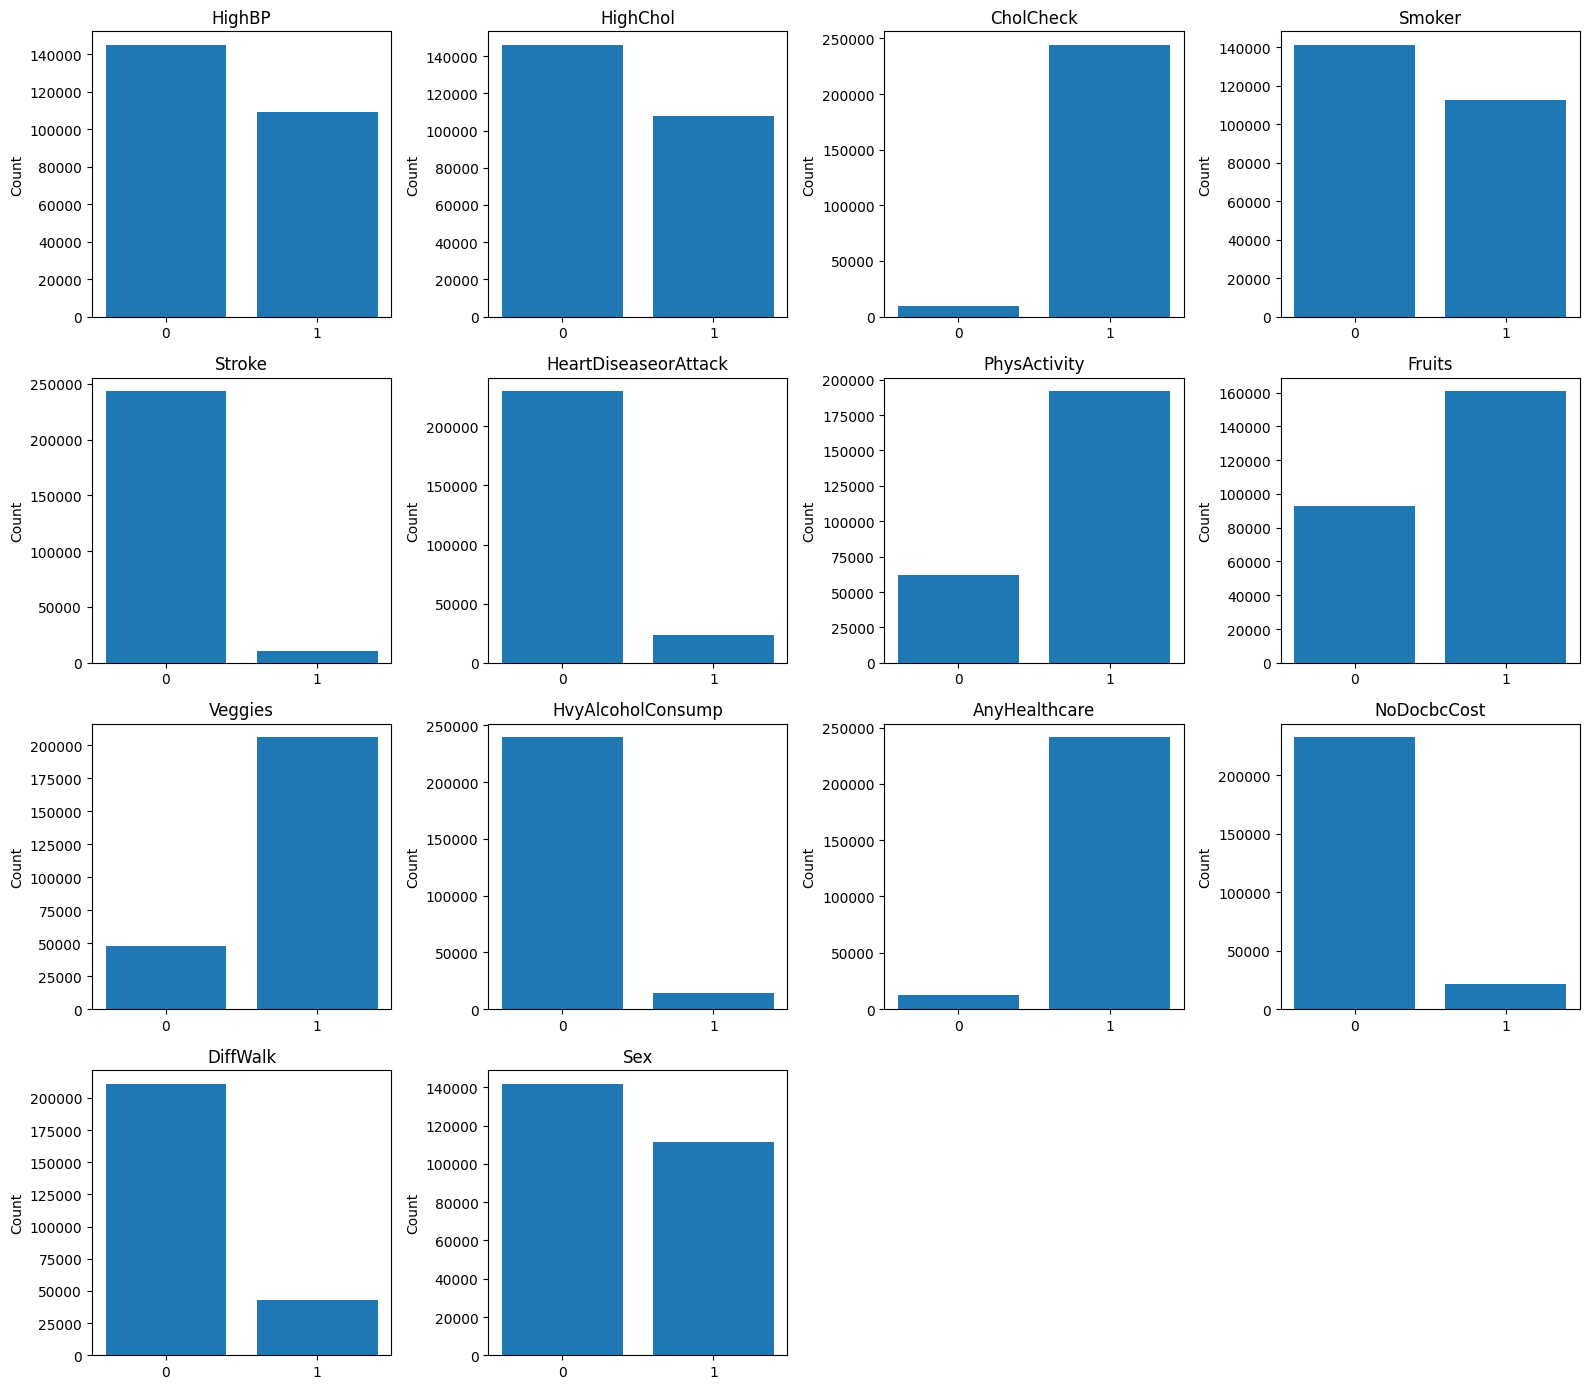

In [ ]:
binary_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]

fig, axes = plt.subplots(4, 4, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(binary_features):
    counts = df[col].value_counts().sort_index()

    axes[i].bar(counts.index.astype(str), counts.values)
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")

for j in range(len(binary_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

##Feature relationships

**Feature relationships**

The strongest positive relationships with diabetes are observed for **GenHlth (0.29), HighBP (0.26), BMI (0.23), DiffWalk (0.22), and HighChol (0.20)**. Heart disease, age, and physical health also show moderate positive associations.

Negative relationships are strongest for **Income (-0.16), Education (-0.12), and PhysActivity (-0.12)**, suggesting that higher socioeconomic status and greater physical activity are associated with lower diabetes prevalence in this sample.

Most correlations remain moderate rather than extremely high, indicating that no single predictor dominates the target relationship and supporting the use of multivariable machine-learning models.

The continuous and ordinal predictors show substantial overlap between diabetic and non-diabetic observations, indicating that no single variable is sufficient to clearly separate the two groups.

**BMI** shows the clearest shift, with diabetic observations generally concentrated at higher values. **PhysHlth** also shows a visible tendency toward worse physical-health scores among diabetic individuals. In contrast, **MentHlth** exhibits considerable overlap between the two classes.

The ordinal variables similarly show gradual rather than sharp differences between classes. This supports the use of multivariable models that can combine several weak-to-moderate signals instead of relying on a single predictor.

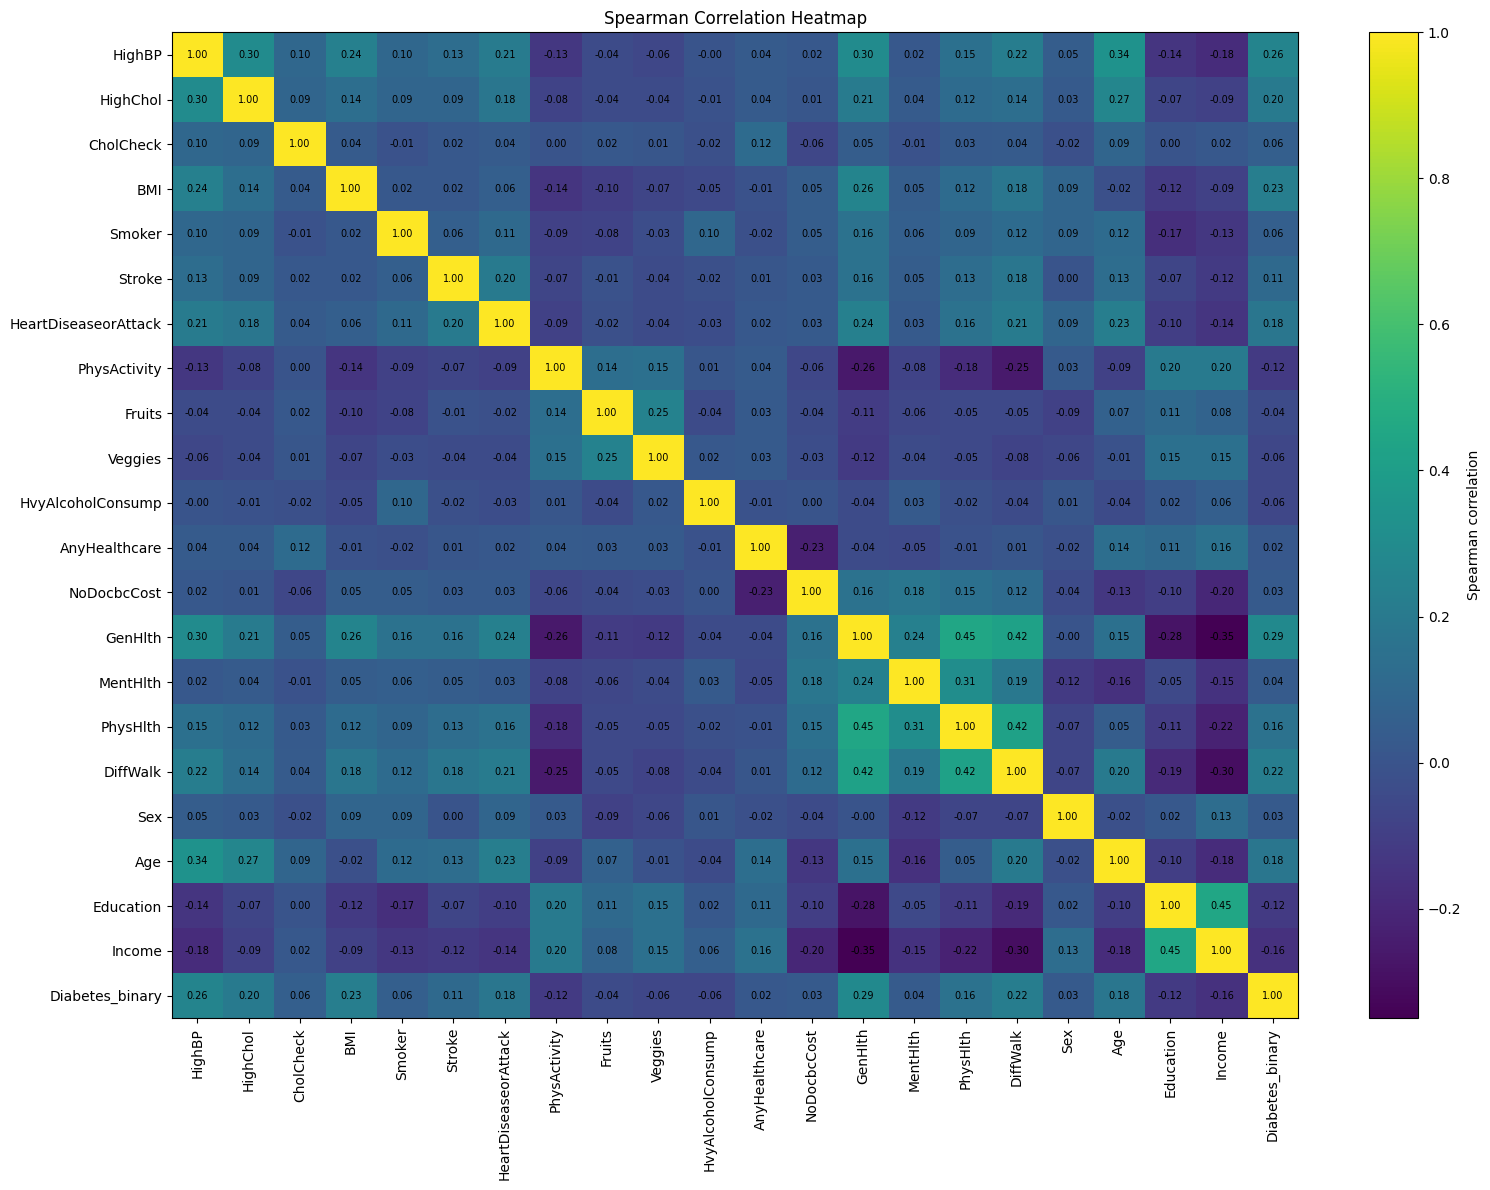

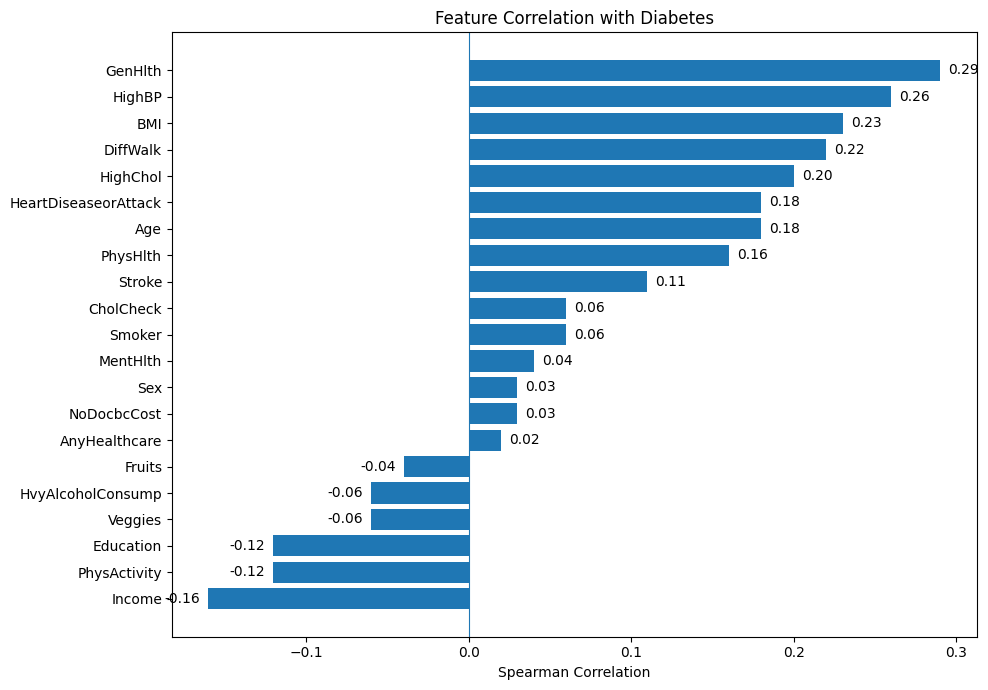

In [ ]:
corr = df.corr(method="spearman").round(2)

plt.figure(figsize=(16, 12))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Spearman correlation")

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90
)
plt.yticks(
    range(len(corr.index)),
    corr.index
)

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(
            j, i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()


target_corr = (
    corr["Diabetes_binary"]
    .drop("Diabetes_binary")
    .sort_values()
)

plt.figure(figsize=(10, 7))
bars = plt.barh(target_corr.index, target_corr.values)

plt.axvline(0, linewidth=0.8)
plt.title("Feature Correlation with Diabetes")
plt.xlabel("Spearman Correlation")
plt.ylabel("")

for bar, value in zip(bars, target_corr.values):
    plt.text(
        value + (0.005 if value >= 0 else -0.005),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        ha="left" if value >= 0 else "right"
    )

plt.tight_layout()
plt.show()

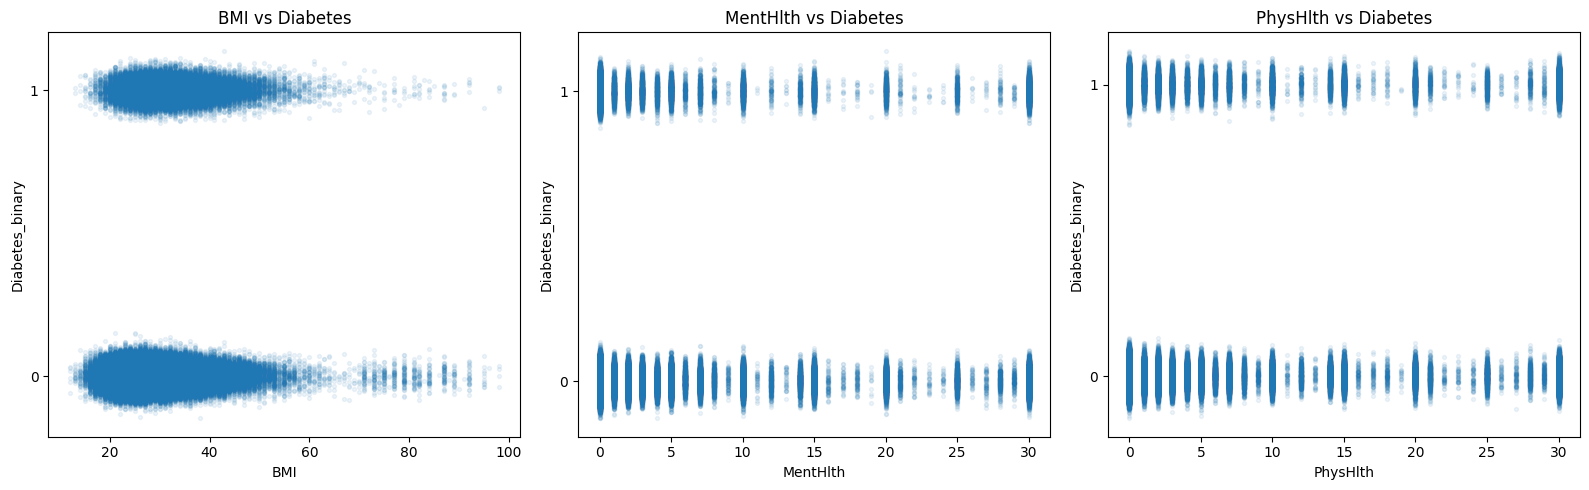

In [ ]:
continuous_features = ["BMI", "MentHlth", "PhysHlth"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

rng = np.random.default_rng(42)

for ax, col in zip(axes, continuous_features):
    y_jitter = df["Diabetes_binary"] + rng.normal(0, 0.03, len(df))

    ax.scatter(
        df[col],
        y_jitter,
        alpha=0.08,
        s=8
    )

    ax.set_title(f"{col} vs Diabetes")
    ax.set_xlabel(col)
    ax.set_ylabel("Diabetes_binary")
    ax.set_yticks([0, 1])

plt.tight_layout()
plt.show()

##Target Characteristic

,Non-diabetic (%),Diabetic (%)
HighBP,37.6600,75.2700
HighChol,38.4300,67.0100
CholCheck,95.7700,99.3200
Smoker,43.1000,51.8200
Stroke,3.2200,9.2500
HeartDiseaseorAttack,7.3400,22.2900
PhysActivity,77.6900,63.0500
Fruits,64.2200,58.5400
Veggies,82.0300,75.6400
HvyAlcoholConsump,6.1500,2.3500


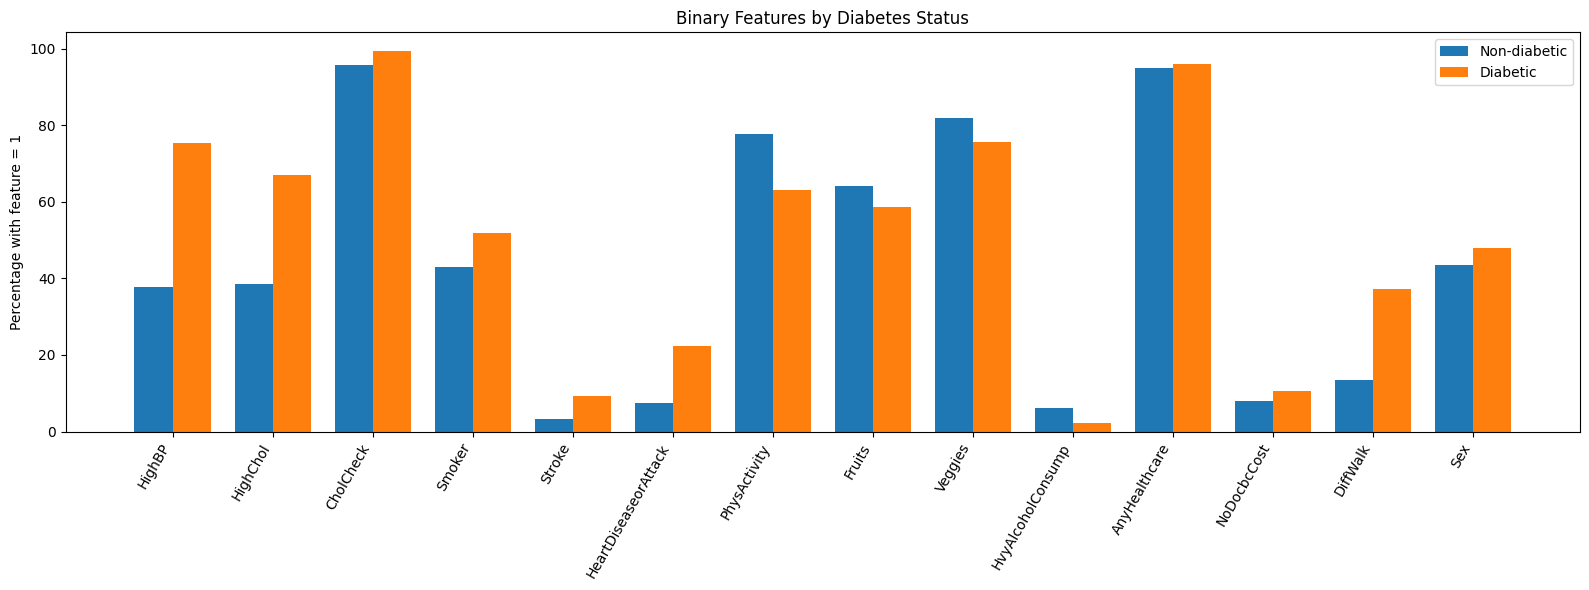

Diabetes_binary        0       1
BMI       mean   27.8100 31.9400
          median 27.0000 31.0000
MentHlth  mean    2.9800  4.4600
          median  0.0000  0.0000
PhysHlth  mean    3.6400  7.9500
          median  0.0000  1.0000
GenHlth   mean    2.3900  3.2900
          median  2.0000  3.0000
Age       mean    7.8100  9.3800
          median  8.0000 10.0000
Education mean    5.1000  4.7500
          median  5.0000  5.0000
Income    mean    6.1900  5.2100
          median  7.0000  6.0000

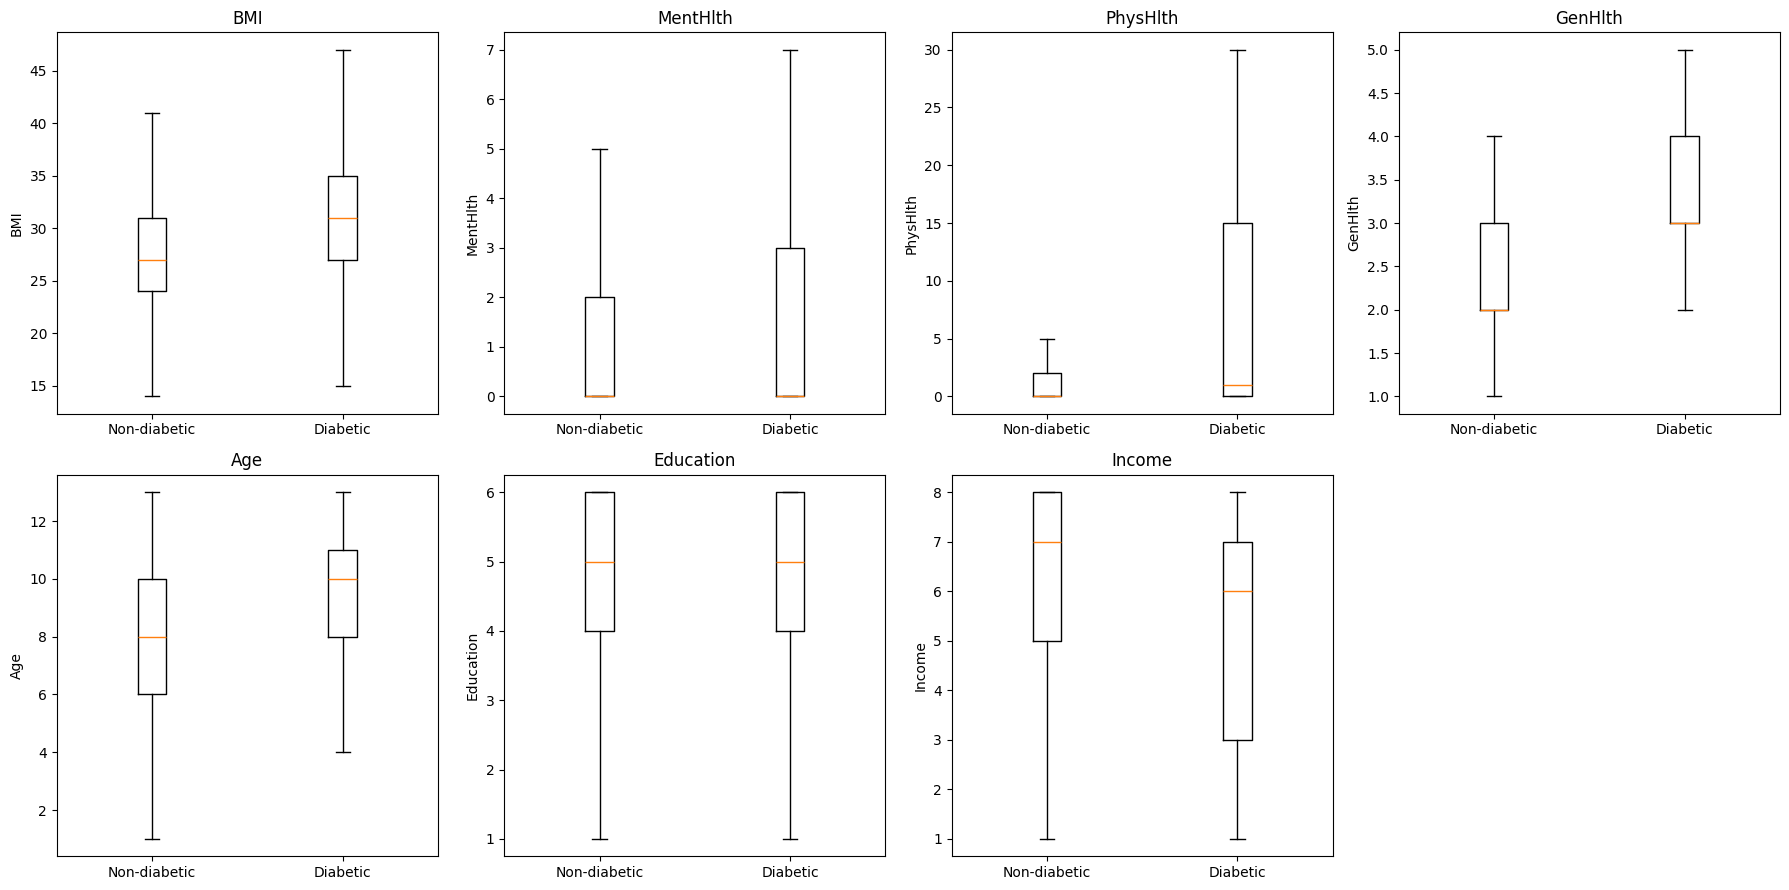

In [ ]:
binary_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]

non_binary_features = [
    "BMI", "MentHlth", "PhysHlth",
    "GenHlth", "Age", "Education", "Income"
]

binary_comparison = (
    df.groupby("Diabetes_binary")[binary_features]
    .mean()
    .T
    .mul(100)
    .round(2)
)

binary_comparison.columns = ["Non-diabetic (%)", "Diabetic (%)"]

display(binary_comparison)

x = np.arange(len(binary_features))
width = 0.38

plt.figure(figsize=(16, 6))
plt.bar(
    x - width / 2,
    binary_comparison["Non-diabetic (%)"],
    width,
    label="Non-diabetic"
)
plt.bar(
    x + width / 2,
    binary_comparison["Diabetic (%)"],
    width,
    label="Diabetic"
)

plt.xticks(x, binary_features, rotation=60, ha="right")
plt.ylabel("Percentage with feature = 1")
plt.title("Binary Features by Diabetes Status")
plt.legend()
plt.tight_layout()
plt.show()


numeric_comparison = (
    df.groupby("Diabetes_binary")[non_binary_features]
    .agg(["mean", "median"])
    .T
    .round(2)
)

display(numeric_comparison)


fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for ax, col in zip(axes, non_binary_features):
    group_0 = df.loc[df["Diabetes_binary"] == 0, col]
    group_1 = df.loc[df["Diabetes_binary"] == 1, col]

    ax.boxplot(
        [group_0, group_1],
        labels=["Non-diabetic", "Diabetic"],
        showfliers=False
    )

    ax.set_title(col)
    ax.set_ylabel(col)

for j in range(len(non_binary_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

##Multi-panel Figure for report


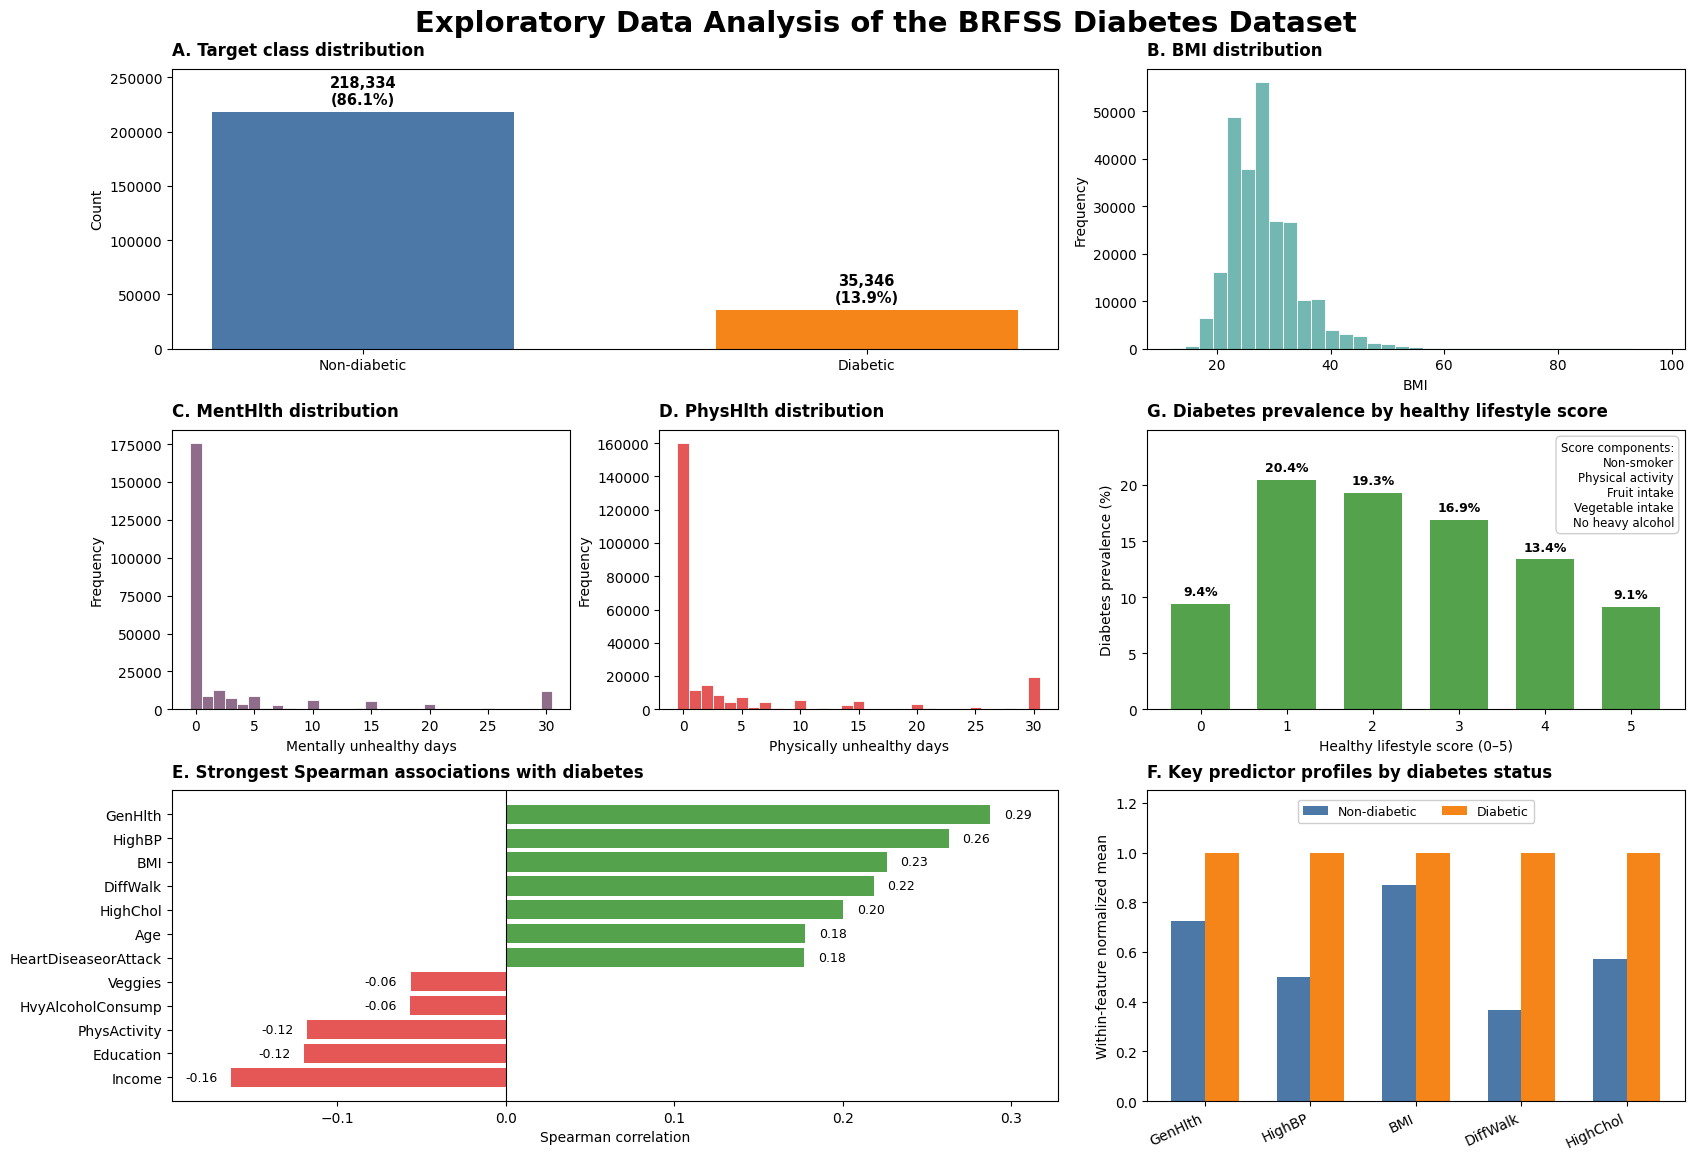

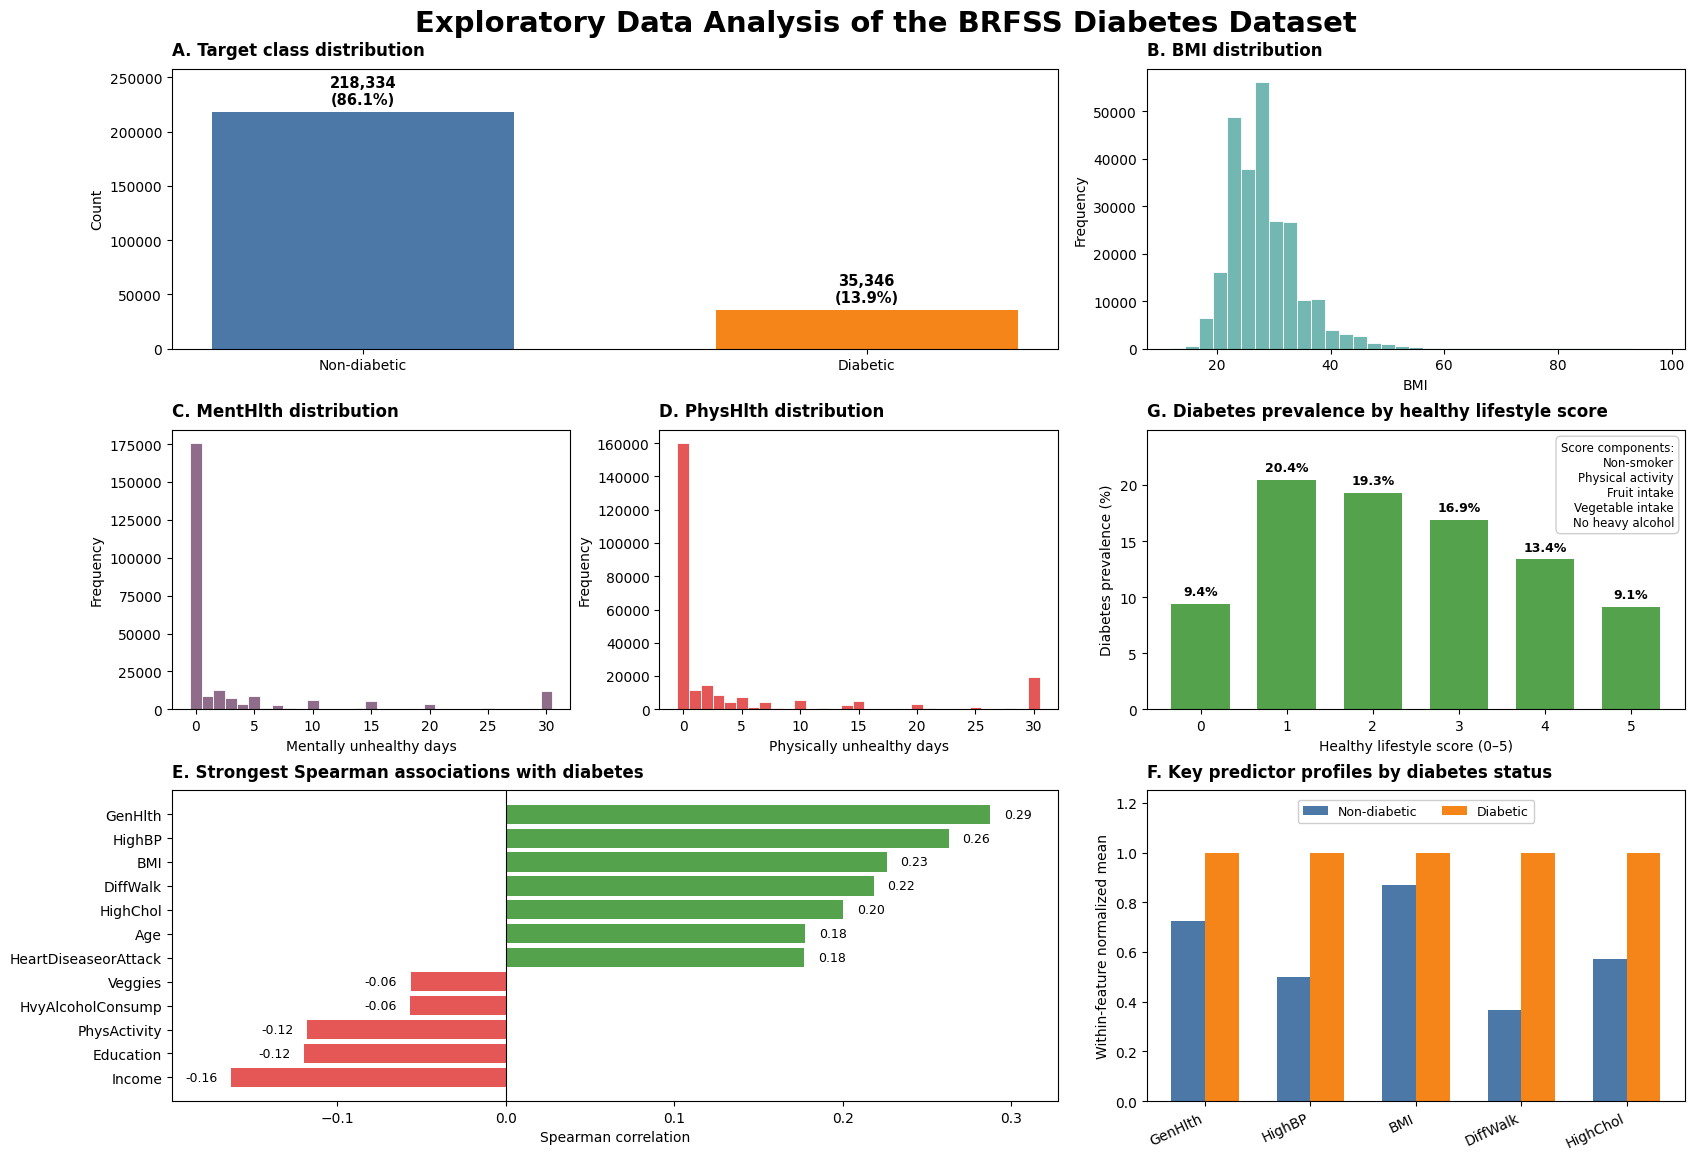

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

target = "Diabetes_binary"

colors = {
    "blue": "#4C78A8",
    "orange": "#F58518",
    "green": "#54A24B",
    "red": "#E45756",
    "purple": "#8E6C8A",
    "teal": "#72B7B2"
}

scatter_df = df.sample(min(5000, len(df)), random_state=42).copy()

fig = plt.figure(figsize=(17, 12))

gs = GridSpec(
    3,
    3,
    figure=fig,
    width_ratios=[1.0, 1.0, 1.35],
    height_ratios=[0.9, 0.9, 1.0],
    hspace=0.28,
    wspace=0.20
)

# =========================================================
# A. Target class distribution
# =========================================================
axA = fig.add_subplot(gs[0, 0:2])

target_counts = df[target].value_counts().sort_index()

bars = axA.bar(
    ["Non-diabetic", "Diabetic"],
    target_counts.values,
    color=[colors["blue"], colors["orange"]],
    width=0.60
)

axA.set_title(
    "A. Target class distribution",
    loc="left",
    fontweight="bold",
    pad=10
)

axA.set_ylabel("Count")
axA.set_ylim(0, target_counts.max() * 1.18)

for bar, value in zip(bars, target_counts.values):
    axA.text(
        bar.get_x() + bar.get_width() / 2,
        value + target_counts.max() * 0.02,
        f"{value:,}\n({value / len(df):.1%})",
        ha="center",
        va="bottom",
        fontsize=10.5,
        fontweight="bold"
    )

# =========================================================
# B. BMI distribution
# =========================================================
axB = fig.add_subplot(gs[0, 2])

axB.hist(
    df["BMI"],
    bins=35,
    color=colors["teal"],
    edgecolor="white",
    linewidth=0.6
)

axB.set_title(
    "B. BMI distribution",
    loc="left",
    fontweight="bold",
    pad=10
)

axB.set_xlabel("BMI")
axB.set_ylabel("Frequency")

# =========================================================
# C. MentHlth distribution
# =========================================================
axC = fig.add_subplot(gs[1, 0])

axC.hist(
    df["MentHlth"],
    bins=np.arange(-0.5, 31.5, 1),
    color=colors["purple"],
    edgecolor="white",
    linewidth=0.6
)

axC.set_title(
    "C. MentHlth distribution",
    loc="left",
    fontweight="bold",
    pad=10
)

axC.set_xlabel("Mentally unhealthy days")
axC.set_ylabel("Frequency")

# =========================================================
# D. PhysHlth distribution
# =========================================================
axD = fig.add_subplot(gs[1, 1])

axD.hist(
    df["PhysHlth"],
    bins=np.arange(-0.5, 31.5, 1),
    color=colors["red"],
    edgecolor="white",
    linewidth=0.6
)

axD.set_title(
    "D. PhysHlth distribution",
    loc="left",
    fontweight="bold",
    pad=10
)

axD.set_xlabel("Physically unhealthy days")
axD.set_ylabel("Frequency")

# =========================================================
# G. Diabetes prevalence by healthy lifestyle score
# =========================================================
axG = fig.add_subplot(gs[1, 2])

lifestyle_df = df.copy()

lifestyle_df["HealthyLifestyleScore"] = (
    (lifestyle_df["Smoker"] == 0).astype(int)
    + (lifestyle_df["PhysActivity"] == 1).astype(int)
    + (lifestyle_df["Fruits"] == 1).astype(int)
    + (lifestyle_df["Veggies"] == 1).astype(int)
    + (lifestyle_df["HvyAlcoholConsump"] == 0).astype(int)
)

lifestyle_summary = (
    lifestyle_df
    .groupby("HealthyLifestyleScore")[target]
    .agg(["mean", "count"])
    .reset_index()
)

lifestyle_summary["DiabetesPrevalence"] = (
    lifestyle_summary["mean"] * 100
)

bars = axG.bar(
    lifestyle_summary["HealthyLifestyleScore"],
    lifestyle_summary["DiabetesPrevalence"],
    color=colors["green"],
    width=0.68
)

axG.set_title(
    "G. Diabetes prevalence by healthy lifestyle score",
    loc="left",
    fontweight="bold",
    pad=10
)

axG.set_xlabel("Healthy lifestyle score (0–5)")
axG.set_ylabel("Diabetes prevalence (%)")

axG.set_xticks(
    lifestyle_summary["HealthyLifestyleScore"]
)

axG.set_ylim(
    0,
    lifestyle_summary["DiabetesPrevalence"].max() * 1.22
)

for bar, prevalence, count in zip(
    bars,
    lifestyle_summary["DiabetesPrevalence"],
    lifestyle_summary["count"]
):
    axG.text(
        bar.get_x() + bar.get_width() / 2,
        prevalence + lifestyle_summary["DiabetesPrevalence"].max() * 0.025,
        f"{prevalence:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

axG.text(
    0.98,
    0.96,
    "Score components:\n"
    "Non-smoker\n"
    "Physical activity\n"
    "Fruit intake\n"
    "Vegetable intake\n"
    "No heavy alcohol",
    transform=axG.transAxes,
    ha="right",
    va="top",
    fontsize=8.5,
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="0.80",
        alpha=0.95
    )
)
# =========================================================
# E. Feature-target Spearman correlations
# =========================================================
axE = fig.add_subplot(gs[2, 0:2])

corr_target = (
    df.corr(method="spearman")[target]
    .drop(target)
    .sort_values()
)

top_corr = pd.concat([
    corr_target.head(5),
    corr_target.tail(7)
]).drop_duplicates()

corr_colors = [
    colors["green"] if value > 0 else colors["red"]
    for value in top_corr.values
]

bars_e = axE.barh(
    top_corr.index,
    top_corr.values,
    color=corr_colors
)

axE.axvline(
    0,
    color="black",
    linewidth=0.8
)

axE.set_title(
    "E. Strongest Spearman associations with diabetes",
    loc="left",
    fontweight="bold",
    pad=10
)

axE.set_xlabel("Spearman correlation")

# thêm khoảng trống 2 phía để text value không chạm mép
axE.set_xlim(
    min(top_corr.min() - 0.035, -0.18),
    max(top_corr.max() + 0.04, 0.32)
)

for bar, value in zip(bars_e, top_corr.values):
    y = bar.get_y() + bar.get_height() / 2

    if value >= 0:
        axE.text(
            value + 0.008,
            y,
            f"{value:.2f}",
            va="center",
            ha="left",
            fontsize=9
        )
    else:
        axE.text(
            value - 0.008,
            y,
            f"{value:.2f}",
            va="center",
            ha="right",
            fontsize=9
        )

# =========================================================
# F. Key predictor profiles
# =========================================================
axF = fig.add_subplot(gs[2, 2])

key_features = [
    "GenHlth",
    "HighBP",
    "BMI",
    "DiffWalk",
    "HighChol"
]

group_means = (
    df.groupby(target)[key_features]
    .mean()
    .T
)

normalized = group_means.div(
    group_means.max(axis=1),
    axis=0
)

x = np.arange(len(key_features))
width = 0.32

axF.bar(
    x - width / 2,
    normalized[0],
    width,
    label="Non-diabetic",
    color=colors["blue"]
)

axF.bar(
    x + width / 2,
    normalized[1],
    width,
    label="Diabetic",
    color=colors["orange"]
)

axF.set_xticks(x)
axF.set_xticklabels(
    key_features,
    rotation=25,
    ha="right"
)

axF.set_ylabel("Within-feature normalized mean")

axF.set_title(
    "F. Key predictor profiles by diabetes status",
    loc="left",
    fontweight="bold",
    pad=10
)

# tạo headroom riêng cho legend
axF.set_ylim(0, 1.25)

# legend nằm trong chart, trong vùng headroom phía trên
axF.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 0.99),
    ncol=2,
    frameon=True,
    facecolor="white",
    edgecolor="0.80",
    framealpha=0.95,
    fontsize=9
)

# =========================================================
# Figure title
# =========================================================
fig.suptitle(
    "Exploratory Data Analysis of the BRFSS Diabetes Dataset",
    fontsize=21,
    fontweight="bold",
    y=0.98
)

plt.subplots_adjust(
    top=0.93,
    bottom=0.07,
    left=0.08,
    right=0.97
)

plt.show()

#Data Cleaning

##Invalid Check

**Error check**

All variables fall within their documented coding ranges, with **no invalid values detected**. The observed values are therefore consistent with the BRFSS variable definitions, and no corrections or removals are required at this stage.

In [ ]:
expected_ranges = {
    "HighBP": (0, 1),
    "HighChol": (0, 1),
    "CholCheck": (0, 1),
    "BMI": (1, 100),
    "Smoker": (0, 1),
    "Stroke": (0, 1),
    "HeartDiseaseorAttack": (0, 1),
    "PhysActivity": (0, 1),
    "Fruits": (0, 1),
    "Veggies": (0, 1),
    "HvyAlcoholConsump": (0, 1),
    "AnyHealthcare": (0, 1),
    "NoDocbcCost": (0, 1),
    "GenHlth": (1, 5),
    "MentHlth": (0, 30),
    "PhysHlth": (0, 30),
    "DiffWalk": (0, 1),
    "Sex": (0, 1),
    "Age": (1, 13),
    "Education": (1, 6),
    "Income": (1, 8),
    "Diabetes_binary": (0, 1)
}

error_check = []

for col, (lower, upper) in expected_ranges.items():
    invalid_mask = ~df[col].between(lower, upper)
    error_check.append({
        "Variable": col,
        "Expected range": f"{lower}–{upper}",
        "Observed min": df[col].min(),
        "Observed max": df[col].max(),
        "Invalid values": invalid_mask.sum()
    })

error_check = pd.DataFrame(error_check)

display(error_check)

print(f"Total invalid cells: {error_check['Invalid values'].sum():,}")

,Variable,Expected range,Observed min,Observed max,Invalid values
0,HighBP,0–1,0,1,0
1,HighChol,0–1,0,1,0
2,CholCheck,0–1,0,1,0
3,BMI,1–100,12,98,0
4,Smoker,0–1,0,1,0
5,Stroke,0–1,0,1,0
6,HeartDiseaseorAttack,0–1,0,1,0
7,PhysActivity,0–1,0,1,0
8,Fruits,0–1,0,1,0
9,Veggies,0–1,0,1,0


Total invalid cells: 0


##Outlier Handling

**Outlier handling**

The IQR rule identifies **3.88% of BMI**, **14.27% of MentHlth**, and **16.14% of PhysHlth** observations as statistical outliers.

However, these observations are retained. BMI values remain within the documented valid range, while MentHlth and PhysHlth are bounded survey variables ranging from 0 to 30 days and are strongly zero-inflated. Their high IQR-based outlier rates therefore reflect the underlying distribution rather than clear data errors.

No observations are removed or capped. The original values are preserved to avoid eliminating potentially meaningful high-risk health profiles.

In [ ]:
continuous_features = ["BMI", "MentHlth", "PhysHlth"]

outlier_summary = []

for col in continuous_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()

    outlier_summary.append({
        "Variable": col,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Lower bound": round(lower_bound, 2),
        "Upper bound": round(upper_bound, 2),
        "Outliers": outliers,
        "Outlier rate (%)": round(outliers / len(df) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,Variable,Q1,Q3,IQR,Lower bound,Upper bound,Outliers,Outlier rate (%)
0,BMI,24.0000,31.0000,7.0000,13.5000,41.5000,9847,3.8800
1,MentHlth,0.0000,2.0000,2.0000,-3.0000,5.0000,36208,14.2700
2,PhysHlth,0.0000,3.0000,3.0000,-4.5000,7.5000,40949,16.1400


#Data Preparation

**Data preparation**

The cleaned dataset was prepared for modeling by separating the predictors from the binary diabetes target and organizing the predictors into **binary, ordinal, and continuous features** according to their measurement structure.

The dataset was then divided into a **training set and a locked test set using stratified sampling** so that the diabetes prevalence remained consistent across both subsets. The test set was reserved for final evaluation only and was not used during model development.

A **Stratified K-Fold cross-validation** strategy was defined on the training data to provide more stable model evaluation while preserving the class distribution within each fold.

Because Logistic Regression is sensitive to feature scale, **StandardScaler** was applied within its modeling pipeline. Tree-based boosting models do not require the same scaling step.

The final preparation therefore preserves all valid observations, retains the original predictors, and establishes a consistent validation framework for the baseline, boosting screening, and later hyperparameter optimization.

In [ ]:
X = df.drop(columns=["Diabetes_binary"]).copy()
y = df["Diabetes_binary"].copy()

binary_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]

ordinal_features = [
    "GenHlth", "Age", "Education", "Income"
]

continuous_features = [
    "BMI", "MentHlth", "PhysHlth"
]

feature_summary = pd.DataFrame({
    "Feature": X.columns,
    "Type": [
        "Binary" if col in binary_features
        else "Ordinal" if col in ordinal_features
        else "Continuous"
        for col in X.columns
    ],
    "Unique values": [X[col].nunique() for col in X.columns],
    "Minimum": [X[col].min() for col in X.columns],
    "Maximum": [X[col].max() for col in X.columns]
})

print("Predictor matrix shape:", X.shape)
print("Target vector shape:", y.shape)

display(feature_summary)

target_summary = (
    y.value_counts()
    .sort_index()
    .rename_axis("Class")
    .to_frame("Count")
)

target_summary["Percentage"] = (
    target_summary["Count"] / len(y) * 100
).round(2)

display(target_summary)

Predictor matrix shape: (253680, 21)
Target vector shape: (253680,)


,Feature,Type,Unique values,Minimum,Maximum
0,HighBP,Binary,2,0,1
1,HighChol,Binary,2,0,1
2,CholCheck,Binary,2,0,1
3,BMI,Continuous,84,12,98
4,Smoker,Binary,2,0,1
5,Stroke,Binary,2,0,1
6,HeartDiseaseorAttack,Binary,2,0,1
7,PhysActivity,Binary,2,0,1
8,Fruits,Binary,2,0,1
9,Veggies,Binary,2,0,1


,Count,Percentage
Class,,
0,218334,86.0700
1,35346,13.9300


In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold

TEST_SIZE = 0.20
N_SPLITS = 5
SEED = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=SEED
)

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

split_summary = pd.DataFrame({
    "Dataset": ["Full dataset", "Training set", "Locked test set"],
    "Observations": [
        len(y),
        len(y_train),
        len(y_test)
    ],
    "Non-diabetic": [
        (y == 0).sum(),
        (y_train == 0).sum(),
        (y_test == 0).sum()
    ],
    "Diabetic": [
        (y == 1).sum(),
        (y_train == 1).sum(),
        (y_test == 1).sum()
    ],
    "Diabetes rate (%)": [
        (y == 1).mean() * 100,
        (y_train == 1).mean() * 100,
        (y_test == 1).mean() * 100
    ]
})

split_summary["Diabetes rate (%)"] = split_summary["Diabetes rate (%)"].round(2)

display(split_summary)

print(f"Training features: {X_train.shape}")
print(f"Locked test features: {X_test.shape}")
print(f"Cross-validation: {N_SPLITS}-fold StratifiedKFold")

print("\nCapacity size in locked test set:")

capacity_summary = pd.DataFrame({
    "Capacity": [f"{k:.1%}" for k in CAPACITIES],
    "Number selected": [
        int(np.ceil(len(X_test) * k))
        for k in CAPACITIES
    ]
})

display(capacity_summary)

,Dataset,Observations,Non-diabetic,Diabetic,Diabetes rate (%)
0,Full dataset,253680,218334,35346,13.9300
1,Training set,202944,174667,28277,13.9300
2,Locked test set,50736,43667,7069,13.9300


Training features: (202944, 21)
Locked test features: (50736, 21)
Cross-validation: 5-fold StratifiedKFold

Capacity size in locked test set:


,Capacity,Number selected
0,0.5%,254
1,1.0%,508
2,2.5%,1269
3,5.0%,2537
4,10.0%,5074
5,20.0%,10148


#Model Training

##Baseline Model

**Baseline model performance**

The untuned Logistic Regression baseline achieves an **OOF PR-AUC of 0.4073** and **ROC-AUC of 0.8228**.

Precision@K is highest under the most restrictive capacity and gradually decreases as more patients are selected:

| Capacity | Precision@K |
|---:|---:|
| **0.5%** | **0.6197** |
| **1%** | **0.6064** |
| **2.5%** | **0.5706** |
| **5%** | **0.5265** |
| **10%** | **0.4649** |
| **20%** | **0.3884** |

This baseline provides the reference performance that the boosting models should improve upon.

,Metric,OOF score
0,PR-AUC,0.4073
1,ROC-AUC,0.8228


,Capacity,Selected,Precision@K
0,0.5%,1015,0.6197
1,1.0%,2030,0.6064
2,2.5%,5074,0.5706
3,5.0%,10148,0.5265
4,10.0%,20295,0.4649
5,20.0%,40589,0.3884


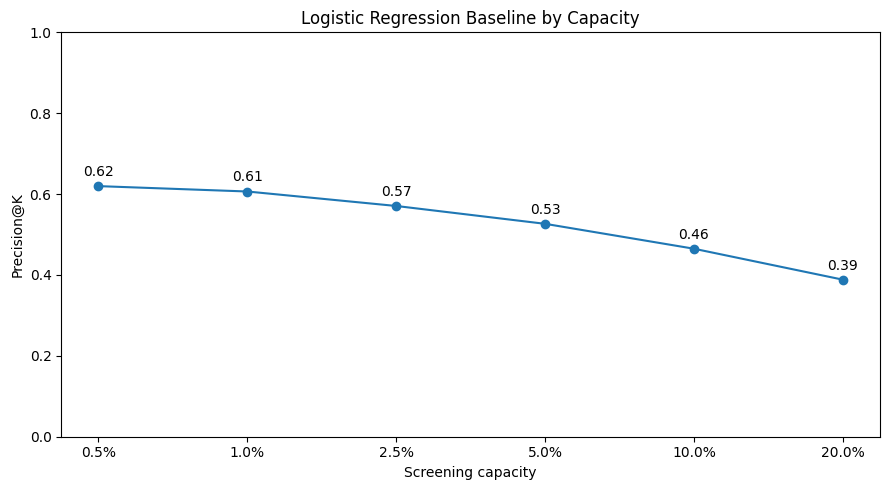

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import average_precision_score, roc_auc_score

def precision_at_k(y_true, y_score, k):
    n_selected = int(np.ceil(len(y_true) * k))
    top_idx = np.argsort(y_score)[::-1][:n_selected]
    return np.mean(np.asarray(y_true)[top_idx])

baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ))
])

baseline_oof_prob = cross_val_predict(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

baseline_summary = pd.DataFrame({
    "Metric": ["PR-AUC", "ROC-AUC"],
    "OOF score": [
        average_precision_score(y_train, baseline_oof_prob),
        roc_auc_score(y_train, baseline_oof_prob)
    ]
})

baseline_summary["OOF score"] = baseline_summary["OOF score"].round(4)

baseline_capacity = pd.DataFrame({
    "Capacity": [f"{k:.1%}" for k in CAPACITIES],
    "Selected": [
        int(np.ceil(len(y_train) * k))
        for k in CAPACITIES
    ],
    "Precision@K": [
        precision_at_k(y_train, baseline_oof_prob, k)
        for k in CAPACITIES
    ]
})

baseline_capacity["Precision@K"] = baseline_capacity["Precision@K"].round(4)

display(baseline_summary)
display(baseline_capacity)

plt.figure(figsize=(9, 5))
plt.plot(
    baseline_capacity["Capacity"],
    baseline_capacity["Precision@K"],
    marker="o"
)
plt.ylabel("Precision@K")
plt.xlabel("Screening capacity")
plt.title("Logistic Regression Baseline by Capacity")
plt.ylim(0, 1)

for i, value in enumerate(baseline_capacity["Precision@K"]):
    plt.text(
        i,
        value + 0.025,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

##Global Model

##Preliminary boosting screening

**Boosting model selection**

The preliminary EDA indicates that the diabetes outcome is influenced by multiple predictors with mostly **weak-to-moderate individual relationships**, rather than by a single dominant feature. Several predictors also show non-linear, ordinal, and potentially interacting effects, while the two target groups substantially overlap across individual variables.

These patterns suggest that a simple linear decision boundary may be insufficient to capture the underlying structure. Therefore, tree-based boosting models are selected because they can combine multiple moderate signals, model non-linear relationships, and capture interactions between health, behavioral, and demographic variables.

Four boosting families are screened: **HistGradientBoosting, XGBoost, LightGBM, and CatBoost**. They are first compared using the same cross-validation framework with standard configurations, after which the strongest candidate is selected for deeper optimization.

**Boosting model comparison**

| Model | Advantages | Limitations |
|---|---|---|
| **HistGradientBoosting** | Fast and memory-efficient on large tabular datasets; integrated directly with scikit-learn; handles non-linear relationships well. | Less flexible and less extensively tunable than specialized boosting libraries; fewer advanced optimization options. |
| **XGBoost** | Strong predictive performance; effective regularization; robust handling of complex interactions; highly flexible hyperparameter space. | Can be computationally expensive to tune; performance depends strongly on hyperparameter selection. |
| **LightGBM** | Very fast training; efficient on large datasets; well suited to high-dimensional tabular data; supports flexible tree growth. | Leaf-wise growth can overfit if not carefully controlled; sensitive to parameters such as `num_leaves` and tree depth. |
| **CatBoost** | Strong default performance; robust against overfitting; effective handling of complex feature interactions; usually requires less preprocessing. | Training can be slower than LightGBM; its main advantage for categorical variables is less relevant here because the dataset is already numerically encoded. |

**Boosting model screening results**

Among the four boosting candidates, **LightGBM** achieves the strongest overall screening performance, with the highest **PR-AUC of 0.4346** and **ROC-AUC of 0.8303**.

| Model | PR-AUC | ROC-AUC |
|---|---:|---:|
| **LightGBM** | **0.4346** | **0.8303** |
| HistGradientBoosting | 0.4343 | 0.8301 |
| CatBoost | 0.4254 | 0.8281 |
| XGBoost | 0.4225 | 0.8260 |

LightGBM also performs strongly across all capacity levels:

| Model | 0.5% | 1% | 2.5% | 5% | 10% | 20% |
|---|---:|---:|---:|---:|---:|---:|
| **LightGBM** | **0.7172** | **0.6788** | **0.6171** | **0.5607** | 0.4888 | **0.3989** |
| HistGradientBoosting | 0.7094 | 0.6808 | 0.6153 | 0.5570 | **0.4901** | **0.3989** |
| CatBoost | 0.6778 | 0.6512 | 0.5974 | 0.5471 | 0.4830 | 0.3957 |
| XGBoost | 0.6857 | 0.6493 | 0.5932 | 0.5421 | 0.4793 | 0.3934 |

Although HistGradientBoosting is slightly better at **1% and 10%**, LightGBM provides the strongest overall combination of global ranking performance and Precision@K across capacities. Therefore, **LightGBM is selected for subsequent Optuna optimization**.

**Final model family selection**

Although LightGBM performed slightly better under default screening, XGBoost showed stronger performance after light tuning with class weighting.

| Model | PR-AUC | ROC-AUC |
|---|---:|---:|
| **XGBoost** | **0.4372** | **0.8314** |
| LightGBM | 0.4362 | 0.8311 |

XGBoost also achieved higher Precision@K at most capacity levels:

| Model | 0.5% | 1.0% | 2.5% | 5.0% | 10.0% | 20.0% |
|---|---:|---:|---:|---:|---:|---:|
| **XGBoost** | **0.7084** | **0.6857** | 0.6248 | **0.5617** | **0.4916** | **0.4007** |
| LightGBM | 0.7054 | 0.6768 | **0.6271** | 0.5609 | 0.4902 | 0.4000 |

XGBoost therefore provides the stronger overall balance after light tuning, outperforming LightGBM in PR-AUC, ROC-AUC, and Precision@K at **five of the six capacity levels**.

This suggests that XGBoost has greater optimization potential within the current dataset and modeling setup. Therefore, **XGBoost is selected for deeper Optuna optimization**.

Running HistGradientBoosting...
Running XGBoost...
Running LightGBM...
Running CatBoost...


,Model,PR-AUC,ROC-AUC
0,LightGBM,0.4346,0.8303
1,HistGradientBoosting,0.4343,0.8301
2,CatBoost,0.4254,0.8281
3,XGBoost,0.4225,0.8260


Capacity,0.5%,1.0%,2.5%,5.0%,10.0%,20.0%
Model,,,,,,
CatBoost,0.6778,0.6512,0.5974,0.5471,0.4830,0.3957
HistGradientBoosting,0.7094,0.6808,0.6153,0.5570,0.4901,0.3989
LightGBM,0.7172,0.6788,0.6171,0.5607,0.4888,0.3989
XGBoost,0.6857,0.6493,0.5932,0.5421,0.4793,0.3934


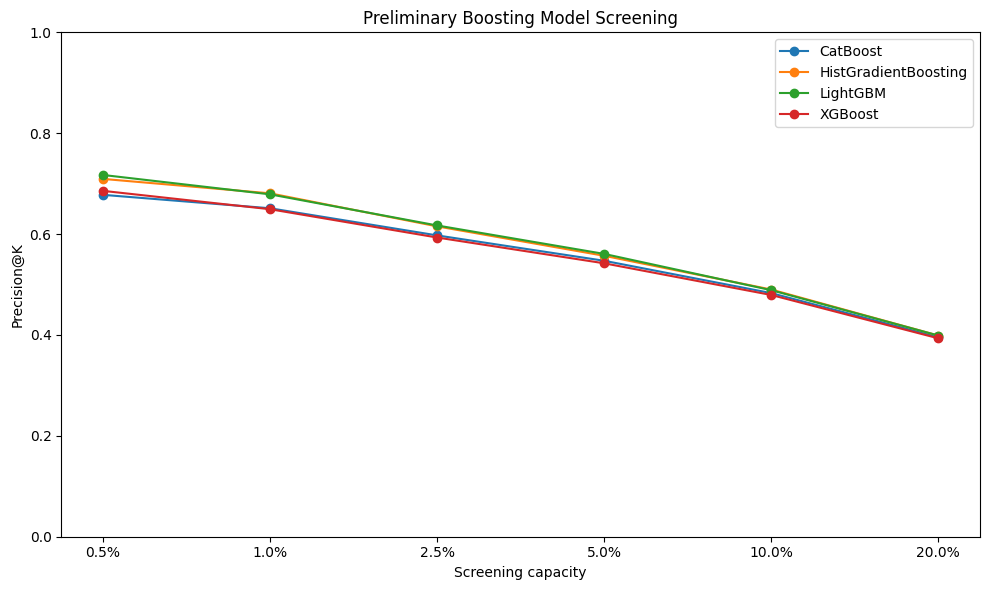

In [ ]:
# from sklearn.base import clone
# from sklearn.model_selection import cross_val_predict
# from sklearn.ensemble import HistGradientBoostingClassifier
# from xgboost import XGBClassifier
# from lightgbm import LGBMClassifier
# from catboost import CatBoostClassifier

# screening_models = {
#     "HistGradientBoosting": HistGradientBoostingClassifier(
#         random_state=SEED
#     ),

#     "XGBoost": XGBClassifier(
#         random_state=SEED,
#         eval_metric="logloss",
#         n_jobs=-1
#     ),

#     "LightGBM": LGBMClassifier(
#         random_state=SEED,
#         n_jobs=-1,
#         verbose=-1
#     ),

#     "CatBoost": CatBoostClassifier(
#         random_seed=SEED,
#         verbose=0
#     )
# }

# screening_results = []
# capacity_results = []

# for model_name, model in screening_models.items():
#     print(f"Running {model_name}...")

#     oof_prob = cross_val_predict(
#         clone(model),
#         X_train,
#         y_train,
#         cv=cv,
#         method="predict_proba",
#         n_jobs=-1
#     )[:, 1]

#     screening_results.append({
#         "Model": model_name,
#         "PR-AUC": average_precision_score(y_train, oof_prob),
#         "ROC-AUC": roc_auc_score(y_train, oof_prob)
#     })

#     for k in CAPACITIES:
#         capacity_results.append({
#             "Model": model_name,
#             "Capacity": f"{k:.1%}",
#             "Precision@K": precision_at_k(
#                 y_train,
#                 oof_prob,
#                 k
#             )
#         })

# screening_results = pd.DataFrame(screening_results)
# screening_results[["PR-AUC", "ROC-AUC"]] = (
#     screening_results[["PR-AUC", "ROC-AUC"]]
#     .round(4)
# )

# capacity_results = pd.DataFrame(capacity_results)
# capacity_results["Precision@K"] = (
#     capacity_results["Precision@K"]
#     .round(4)
# )

# display(
#     screening_results
#     .sort_values("PR-AUC", ascending=False)
#     .reset_index(drop=True)
# )

# capacity_pivot = (
#     capacity_results
#     .pivot(
#         index="Model",
#         columns="Capacity",
#         values="Precision@K"
#     )
# )

# capacity_pivot = capacity_pivot[
#     [f"{k:.1%}" for k in CAPACITIES]
# ]

# display(capacity_pivot)

# plt.figure(figsize=(10, 6))

# for model_name in capacity_pivot.index:
#     plt.plot(
#         capacity_pivot.columns,
#         capacity_pivot.loc[model_name],
#         marker="o",
#         label=model_name
#     )

# plt.xlabel("Screening capacity")
# plt.ylabel("Precision@K")
# plt.title("Preliminary Boosting Model Screening")
# plt.ylim(0, 1)
# plt.legend()
# plt.tight_layout()
# plt.show()

In [ ]:
# from sklearn.model_selection import ParameterGrid

# pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# xgb_grid = {
#     "n_estimators": [300, 600],
#     "max_depth": [3, 5],
#     "learning_rate": [0.03, 0.08],
#     "subsample": [0.8],
#     "colsample_bytree": [0.8],
#     "scale_pos_weight": [1, round(pos_weight, 2)]
# }

# lgbm_grid = {
#     "n_estimators": [300, 600],
#     "num_leaves": [15, 31],
#     "learning_rate": [0.03, 0.08],
#     "subsample": [0.8],
#     "colsample_bytree": [0.8],
#     "class_weight": [None, "balanced"]
# }

# light_tuning_results = []
# light_tuning_capacity = []

# model_spaces = {
#     "XGBoost": (
#         XGBClassifier,
#         xgb_grid
#     ),
#     "LightGBM": (
#         LGBMClassifier,
#         lgbm_grid
#     )
# }

# for model_name, (model_class, param_grid) in model_spaces.items():
#     print(f"\nRunning {model_name} light tuning...")

#     for i, params in enumerate(ParameterGrid(param_grid), start=1):
#         if model_name == "XGBoost":
#             model = model_class(
#                 **params,
#                 random_state=SEED,
#                 eval_metric="logloss",
#                 n_jobs=1
#             )
#         else:
#             model = model_class(
#                 **params,
#                 random_state=SEED,
#                 n_jobs=1,
#                 verbose=-1
#             )

#         oof_prob = cross_val_predict(
#             model,
#             X_train,
#             y_train,
#             cv=cv,
#             method="predict_proba",
#             n_jobs=-1
#         )[:, 1]

#         pr_auc = average_precision_score(y_train, oof_prob)
#         roc_auc = roc_auc_score(y_train, oof_prob)

#         light_tuning_results.append({
#             "Model": model_name,
#             "Config": i,
#             "PR-AUC": pr_auc,
#             "ROC-AUC": roc_auc,
#             "Parameters": params
#         })

#         for k in CAPACITIES:
#             light_tuning_capacity.append({
#                 "Model": model_name,
#                 "Config": i,
#                 "Capacity": f"{k:.1%}",
#                 "Precision@K": precision_at_k(
#                     y_train,
#                     oof_prob,
#                     k
#                 )
#             })

# light_tuning_results = pd.DataFrame(light_tuning_results)
# light_tuning_capacity = pd.DataFrame(light_tuning_capacity)

# best_configs = (
#     light_tuning_results
#     .sort_values(
#         ["Model", "PR-AUC"],
#         ascending=[True, False]
#     )
#     .groupby("Model")
#     .head(1)
#     .reset_index(drop=True)
# )

# best_configs[["PR-AUC", "ROC-AUC"]] = (
#     best_configs[["PR-AUC", "ROC-AUC"]]
#     .round(4)
# )

# display(
#     best_configs[
#         ["Model", "Config", "PR-AUC", "ROC-AUC", "Parameters"]
#     ]
# )

# best_capacity_rows = []

# for _, row in best_configs.iterrows():
#     subset = light_tuning_capacity[
#         (light_tuning_capacity["Model"] == row["Model"]) &
#         (light_tuning_capacity["Config"] == row["Config"])
#     ].copy()

#     best_capacity_rows.append(subset)

# best_capacity = pd.concat(best_capacity_rows)

# best_capacity_pivot = (
#     best_capacity
#     .pivot(
#         index="Model",
#         columns="Capacity",
#         values="Precision@K"
#     )
#     [[f"{k:.1%}" for k in CAPACITIES]]
#     .round(4)
# )

# display(best_capacity_pivot)


Running XGBoost light tuning...

Running LightGBM light tuning...


,Model,Config,PR-AUC,ROC-AUC,Parameters
0,LightGBM,3,0.4362,0.8311,"{'class_weight': None, 'colsample_bytree': 0.8..."
1,XGBoost,5,0.4372,0.8314,"{'colsample_bytree': 0.8, 'learning_rate': 0.0..."


Capacity,0.5%,1.0%,2.5%,5.0%,10.0%,20.0%
Model,,,,,,
LightGBM,0.7054,0.6768,0.6271,0.5609,0.4902,0.4000
XGBoost,0.7084,0.6857,0.6248,0.5617,0.4916,0.4007


##Model Optimization Full Optuna Version

###Optimized Global Best model by Optuna

**XGBoost optimization search space**

The initial Optuna search space is defined using a combination of **official XGBoost documentation, prior clinical machine-learning studies, and the characteristics of the current dataset**.

| Parameter | Search range | Basis for selection |
|---|---:|---|
| `n_estimators` | 200–1000 | Clinical XGBoost studies commonly evaluate several hundred boosting rounds, with some extending toward 800–1000 trees. |
| `max_depth` | 3–8 | Prior clinical studies generally search shallow-to-moderate tree depths to capture interactions while limiting overfitting. |
| `learning_rate` | 0.01–0.20 | This range is commonly used in clinical XGBoost optimization and allows both conservative and faster boosting. |
| `min_child_weight` | 1–15 | Controls whether small child nodes are created and is commonly tuned in clinical XGBoost applications. |
| `gamma` | 0–2 | Allows the model to vary from unrestricted splitting to more conservative tree growth. |
| `subsample` | 0.5–1.0 | XGBoost documentation recommends subsampling as an overfitting-control mechanism; clinical studies commonly search within this interval. |
| `colsample_bytree` | 0.5–1.0 | Allows feature subsampling while remaining within the valid XGBoost range of \((0,1]\). |
| `reg_alpha` | 0–8 | L1 regularization is explored from no regularization to relatively strong regularization. |
| `reg_lambda` | 1–25 | L2 regularization is explored to control leaf-weight complexity and improve model stability. |
| `scale_pos_weight` | 1–6.18 | The lower bound represents no class weighting, while 6.18 is approximately the negative-to-positive class ratio observed in the training data. XGBoost identifies this ratio as a typical value to consider for imbalanced classification. |

The initial ranges are not treated as fixed assumptions. If the best Optuna trials repeatedly reach a search boundary, the range will be reconsidered based on the observed optimization results rather than expanded arbitrarily.

**Sources**

- XGBoost Developers. *XGBoost Parameters*.  
  https://xgboost.readthedocs.io/en/latest/parameter.html

- Clinical AutoML-XGBoost study using Optuna and 5-fold cross-validation.  
  https://pmc.ncbi.nlm.nih.gov/articles/PMC13433797/

- Clinical gradient-boosting study using Optuna-based hyperparameter optimization.  
  https://pmc.ncbi.nlm.nih.gov/articles/PMC13106432/

- Diabetes-related XGBoost study using 5-fold cross-validation and tuning of tree depth, learning rate, subsampling, and feature sampling.  
  https://pmc.ncbi.nlm.nih.gov/articles/PMC11148720/

- Diabetes readmission study applying tuned XGBoost with class-imbalance adjustment and regularization.  
  https://pmc.ncbi.nlm.nih.gov/articles/PMC13574794/

**Global XGBoost optimization**

The global XGBoost model is optimized to maximize **PR-AUC across the full population**, rather than targeting any single screening capacity. All optimization is performed only on the training set using **5-fold Stratified Cross-Validation**, while the locked test set remains untouched.

A **30-trial pilot Optuna search** was first conducted using the initial literature-supported search space above. The best pilot trial achieved a mean 5-fold CV PR-AUC of **0.4391**.

| Parameter | Pilot best value |
|---|---:|
| `n_estimators` | 1000 |
| `max_depth` | 4 |
| `learning_rate` | 0.0310 |
| `min_child_weight` | 2 |
| `gamma` | 0.3557 |
| `subsample` | 0.7808 |
| `colsample_bytree` | 0.5626 |
| `reg_alpha` | 7.2118 |
| `reg_lambda` | 8.5872 |
| `scale_pos_weight` | 1.2735 |

Among all parameters, only **`n_estimators` reached the upper search boundary of 1000**. This suggested that the initial search space may have restricted the number of boosting rounds. The final optimization therefore expanded only the `n_estimators` range, while the remaining parameter ranges were retained.

A **100-trial full Optuna search** was then conducted. The best trial achieved a mean 5-fold CV PR-AUC of **0.4389**.

| Parameter | Full Optuna best value |
|---|---:|
| `n_estimators` | 1500 |
| `max_depth` | 4 |
| `learning_rate` | 0.0181 |
| `min_child_weight` | 1 |
| `gamma` | 1.0903 |
| `subsample` | 0.7522 |
| `colsample_bytree` | 0.9426 |
| `reg_alpha` | 3.0875 |
| `reg_lambda` | 12.9181 |
| `scale_pos_weight` | 1.3235 |

The full search favored **more boosting rounds with a lower learning rate**, suggesting a more gradual boosting process. However, the full search did not materially improve the best pilot PR-AUC, indicating that global performance had largely plateaued around **0.439 PR-AUC**.

For consistent model comparison, the full Optuna configuration was evaluated again using pooled **out-of-fold predictions**. This produced:

| Metric | Score |
|---|---:|
| PR-AUC | **0.4384** |
| ROC-AUC | **0.8316** |

Its Precision@K performance was:

| Capacity | Precision@K |
|---:|---:|
| **0.5%** | **0.7153** |
| **1.0%** | **0.6857** |
| **2.5%** | **0.6259** |
| **5.0%** | **0.5642** |
| **10.0%** | **0.4923** |
| **20.0%** | **0.4007** |

Compared with the light-tuned XGBoost, the full Optuna model achieved a higher pooled PR-AUC (**0.4384 vs. 0.4372**) and equal or better Precision@K at every capacity level. It is therefore retained as the **global XGBoost benchmark** before capacity-specific optimization.

The next stage keeps the same XGBoost model family and validation framework, but changes the optimization objective from global PR-AUC to **Precision@K for each individual capacity level**.

####Pilot Optuna

In [ ]:
# import optuna
# from sklearn.model_selection import cross_val_score
# from xgboost import XGBClassifier

# PILOT_TRIALS = 30

# neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()

# def pilot_objective(trial):
#     params = {
#         "n_estimators": trial.suggest_int("n_estimators", 200, 1000, step=100),
#         "max_depth": trial.suggest_int("max_depth", 3, 8),
#         "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
#         "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
#         "gamma": trial.suggest_float("gamma", 0.0, 2.0),
#         "subsample": trial.suggest_float("subsample", 0.5, 1.0),
#         "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
#         "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 8.0),
#         "reg_lambda": trial.suggest_float("reg_lambda", 1.0, 25.0),
#         "scale_pos_weight": trial.suggest_float(
#             "scale_pos_weight",
#             1.0,
#             neg_pos_ratio
#         )
#     }

#     model = XGBClassifier(
#         **params,
#         objective="binary:logistic",
#         eval_metric="logloss",
#         tree_method="hist",
#         random_state=SEED,
#         n_jobs=1
#     )

#     scores = cross_val_score(
#         model,
#         X_train,
#         y_train,
#         cv=cv,
#         scoring="average_precision",
#         n_jobs=-1
#     )

#     return scores.mean()


# pilot_study = optuna.create_study(
#     direction="maximize",
#     sampler=optuna.samplers.TPESampler(seed=SEED)
# )

# pilot_study.optimize(
#     pilot_objective,
#     n_trials=PILOT_TRIALS,
#     show_progress_bar=True
# )

# pilot_best_params = pilot_study.best_params

# print("Best pilot CV PR-AUC:", round(pilot_study.best_value, 4))

# display(
#     pd.DataFrame(
#         pilot_best_params.items(),
#         columns=["Parameter", "Best value"]
#     )
# )

# search_bounds = {
#     "n_estimators": (200, 1000),
#     "max_depth": (3, 8),
#     "learning_rate": (0.01, 0.20),
#     "min_child_weight": (1, 15),
#     "gamma": (0.0, 2.0),
#     "subsample": (0.5, 1.0),
#     "colsample_bytree": (0.5, 1.0),
#     "reg_alpha": (0.0, 8.0),
#     "reg_lambda": (1.0, 25.0),
#     "scale_pos_weight": (1.0, neg_pos_ratio)
# }

# boundary_check = []

# for param, value in pilot_best_params.items():
#     lower, upper = search_bounds[param]
#     span = upper - lower

#     near_lower = value <= lower + 0.05 * span
#     near_upper = value >= upper - 0.05 * span

#     boundary_check.append({
#         "Parameter": param,
#         "Best value": round(value, 4),
#         "Lower bound": round(lower, 4),
#         "Upper bound": round(upper, 4),
#         "Near boundary": "Yes" if near_lower or near_upper else "No",
#         "Boundary": (
#             "Lower" if near_lower
#             else "Upper" if near_upper
#             else "-"
#         )
#     })

# boundary_check = pd.DataFrame(boundary_check)

# display(boundary_check)

# pilot_trials = pilot_study.trials_dataframe()

# display(
#     pilot_trials[
#         ["number", "value", "state"]
#     ]
#     .sort_values("value", ascending=False)
#     .head(10)
#     .rename(columns={
#         "number": "Trial",
#         "value": "CV PR-AUC",
#         "state": "State"
#     })
#     .round(4)
# )

  0%|          | 0/30 [00:00<?, ?it/s]

Best pilot CV PR-AUC: 0.4391


,Parameter,Best value
0,n_estimators,1000.0000
1,max_depth,4.0000
2,learning_rate,0.0310
3,min_child_weight,2.0000
4,gamma,0.3557
5,subsample,0.7808
6,colsample_bytree,0.5626
7,reg_alpha,7.2118
8,reg_lambda,8.5872
9,scale_pos_weight,1.2735


,Parameter,Best value,Lower bound,Upper bound,Near boundary,Boundary
0,n_estimators,1000.0000,200.0000,1000.0000,Yes,Upper
1,max_depth,4.0000,3.0000,8.0000,No,-
2,learning_rate,0.0310,0.0100,0.2000,No,-
3,min_child_weight,2.0000,1.0000,15.0000,No,-
4,gamma,0.3557,0.0000,2.0000,No,-
5,subsample,0.7808,0.5000,1.0000,No,-
6,colsample_bytree,0.5626,0.5000,1.0000,No,-
7,reg_alpha,7.2118,0.0000,8.0000,No,-
8,reg_lambda,8.5872,1.0000,25.0000,No,-
9,scale_pos_weight,1.2735,1.0000,6.1770,No,-


,Trial,CV PR-AUC,State
28,28,0.4391,COMPLETE
26,26,0.4391,COMPLETE
24,24,0.4389,COMPLETE
27,27,0.4389,COMPLETE
19,19,0.4388,COMPLETE
14,14,0.4387,COMPLETE
29,29,0.4387,COMPLETE
21,21,0.4386,COMPLETE
18,18,0.4386,COMPLETE
23,23,0.4386,COMPLETE


####Optuna Optimized

  0%|          | 0/100 [00:00<?, ?it/s]

Best global CV PR-AUC: 0.4389


,Parameter,Best value
0,n_estimators,1500.0000
1,max_depth,4.0000
2,learning_rate,0.0181
3,min_child_weight,1.0000
4,gamma,1.0903
5,subsample,0.7522
6,colsample_bytree,0.9426
7,reg_alpha,3.0875
8,reg_lambda,12.9181
9,scale_pos_weight,1.3235


,Trial,CV PR-AUC,State
93,93,0.4389,COMPLETE
94,94,0.4388,COMPLETE
87,87,0.4388,COMPLETE
83,83,0.4388,COMPLETE
78,78,0.4388,COMPLETE
72,72,0.4388,COMPLETE
66,66,0.4387,COMPLETE
95,95,0.4387,COMPLETE
90,90,0.4387,COMPLETE
77,77,0.4387,COMPLETE


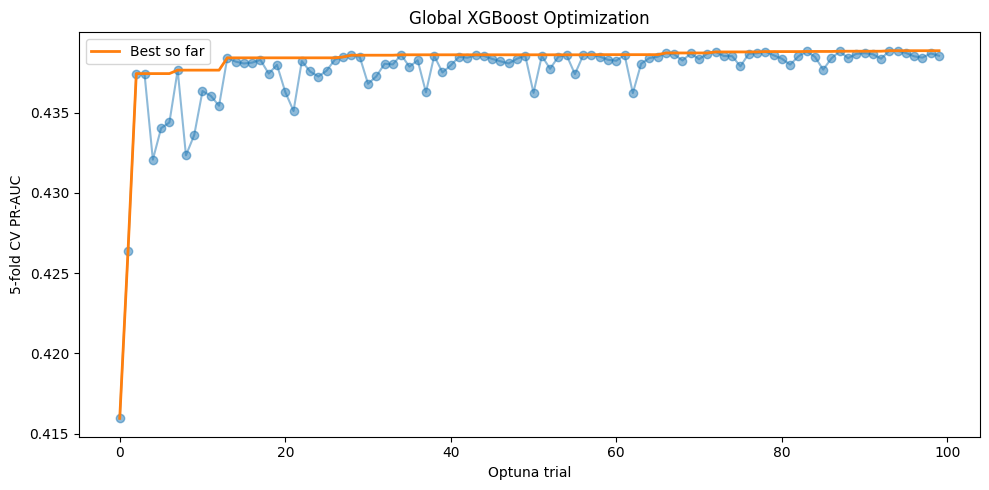

In [ ]:
# FINAL_TRIALS = 100

# def global_objective(trial):
#     params = {
#         "n_estimators": trial.suggest_int("n_estimators", 200, 1600, step=100),
#         "max_depth": trial.suggest_int("max_depth", 3, 8),
#         "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
#         "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
#         "gamma": trial.suggest_float("gamma", 0.0, 2.0),
#         "subsample": trial.suggest_float("subsample", 0.5, 1.0),
#         "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
#         "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 8.0),
#         "reg_lambda": trial.suggest_float("reg_lambda", 1.0, 25.0),
#         "scale_pos_weight": trial.suggest_float(
#             "scale_pos_weight",
#             1.0,
#             neg_pos_ratio
#         )
#     }

#     model = XGBClassifier(
#         **params,
#         objective="binary:logistic",
#         eval_metric="logloss",
#         tree_method="hist",
#         random_state=SEED,
#         n_jobs=1
#     )

#     scores = cross_val_score(
#         model,
#         X_train,
#         y_train,
#         cv=cv,
#         scoring="average_precision",
#         n_jobs=-1
#     )

#     return scores.mean()


# global_study = optuna.create_study(
#     direction="maximize",
#     sampler=optuna.samplers.TPESampler(seed=SEED)
# )

# global_study.optimize(
#     global_objective,
#     n_trials=FINAL_TRIALS,
#     show_progress_bar=True
# )

# global_best_params = global_study.best_params

# print("Best global CV PR-AUC:", round(global_study.best_value, 4))

# display(
#     pd.DataFrame(
#         global_best_params.items(),
#         columns=["Parameter", "Best value"]
#     )
# )

# global_trials = global_study.trials_dataframe()

# display(
#     global_trials[
#         ["number", "value", "state"]
#     ]
#     .sort_values("value", ascending=False)
#     .head(10)
#     .rename(columns={
#         "number": "Trial",
#         "value": "CV PR-AUC",
#         "state": "State"
#     })
#     .round(4)
# )

# global_best_model = XGBClassifier(
#     **global_best_params,
#     objective="binary:logistic",
#     eval_metric="logloss",
#     tree_method="hist",
#     random_state=SEED,
#     n_jobs=-1
# )

# global_best_model.fit(X_train, y_train)

# plt.figure(figsize=(10, 5))
# plt.plot(
#     global_trials["number"],
#     global_trials["value"],
#     marker="o",
#     alpha=0.5
# )

# plt.plot(
#     global_trials["number"],
#     global_trials["value"].cummax(),
#     linewidth=2,
#     label="Best so far"
# )

# plt.xlabel("Optuna trial")
# plt.ylabel("5-fold CV PR-AUC")
# plt.title("Global XGBoost Optimization")
# plt.legend()
# plt.tight_layout()
# plt.show()

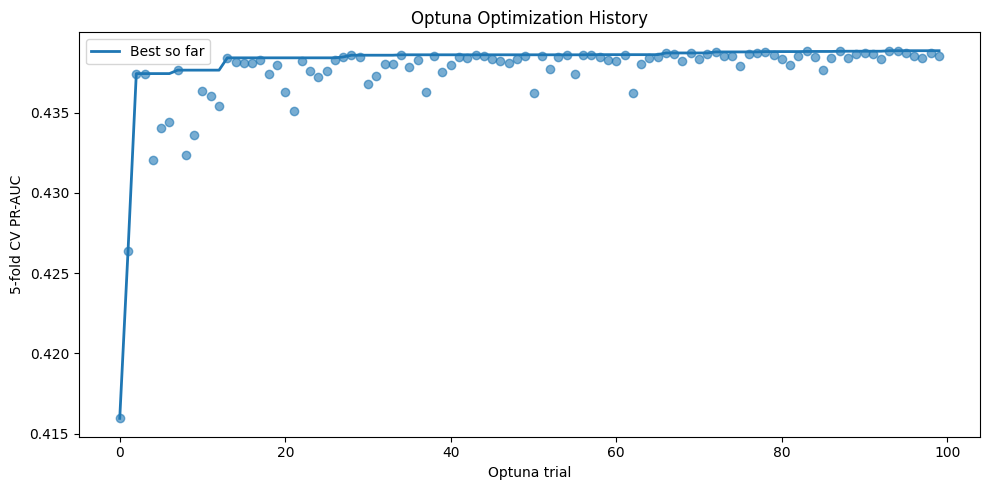

In [ ]:
# import optuna.visualization as vis

# vis.plot_optimization_history(global_study).show()

# vis.plot_param_importances(global_study).show()

# vis.plot_slice(global_study).show()

# vis.plot_parallel_coordinate(global_study).show()

# global_trials = global_study.trials_dataframe()

# plt.figure(figsize=(10, 5))
# plt.scatter(
#     global_trials["number"],
#     global_trials["value"],
#     alpha=0.6
# )

# plt.plot(
#     global_trials["number"],
#     global_trials["value"].cummax(),
#     linewidth=2,
#     label="Best so far"
# )

# plt.xlabel("Optuna trial")
# plt.ylabel("5-fold CV PR-AUC")
# plt.title("Optuna Optimization History")
# plt.legend()
# plt.tight_layout()
# plt.show()

####Result on Capacity

,Model,PR-AUC,ROC-AUC
0,Light-tuned XGBoost,0.4372,0.8314
1,Full Optuna XGBoost,0.4384,0.8316


Capacity,0.5%,1.0%,2.5%,5.0%,10.0%,20.0%
Model,,,,,,
Full Optuna XGBoost,0.7153,0.6857,0.6259,0.5642,0.4923,0.4007
Light-tuned XGBoost,0.7084,0.6857,0.6248,0.5617,0.4916,0.4007


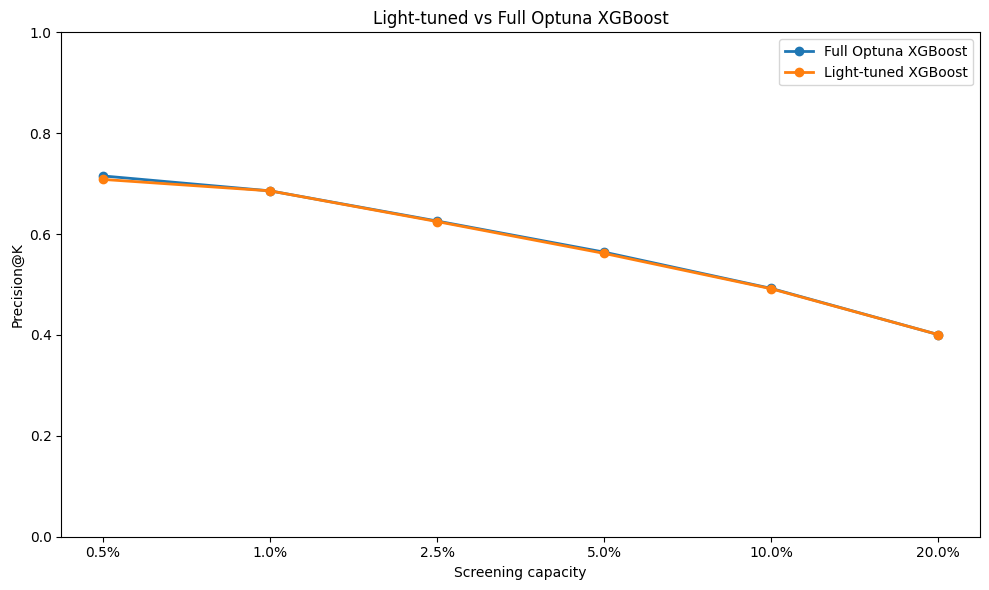

In [ ]:
# light_xgb_params = (
#     best_configs
#     .loc[best_configs["Model"] == "XGBoost", "Parameters"]
#     .iloc[0]
# )

# light_xgb = XGBClassifier(
#     **light_xgb_params,
#     objective="binary:logistic",
#     eval_metric="logloss",
#     tree_method="hist",
#     random_state=SEED,
#     n_jobs=1
# )

# full_xgb = XGBClassifier(
#     **global_best_params,
#     objective="binary:logistic",
#     eval_metric="logloss",
#     tree_method="hist",
#     random_state=SEED,
#     n_jobs=1
# )

# comparison_models = {
#     "Light-tuned XGBoost": light_xgb,
#     "Full Optuna XGBoost": full_xgb
# }

# comparison_results = []
# comparison_capacity = []

# for model_name, model in comparison_models.items():

#     oof_prob = cross_val_predict(
#         model,
#         X_train,
#         y_train,
#         cv=cv,
#         method="predict_proba",
#         n_jobs=-1
#     )[:, 1]

#     comparison_results.append({
#         "Model": model_name,
#         "PR-AUC": average_precision_score(y_train, oof_prob),
#         "ROC-AUC": roc_auc_score(y_train, oof_prob)
#     })

#     for k in CAPACITIES:
#         comparison_capacity.append({
#             "Model": model_name,
#             "Capacity": f"{k:.1%}",
#             "Precision@K": precision_at_k(
#                 y_train,
#                 oof_prob,
#                 k
#             )
#         })

# comparison_results = pd.DataFrame(comparison_results)
# comparison_results[["PR-AUC", "ROC-AUC"]] = (
#     comparison_results[["PR-AUC", "ROC-AUC"]].round(4)
# )

# comparison_capacity = pd.DataFrame(comparison_capacity)

# capacity_compare = (
#     comparison_capacity
#     .pivot(
#         index="Model",
#         columns="Capacity",
#         values="Precision@K"
#     )
#     [[f"{k:.1%}" for k in CAPACITIES]]
#     .round(4)
# )

# display(comparison_results)
# display(capacity_compare)

# plt.figure(figsize=(10, 6))

# for model_name in capacity_compare.index:
#     plt.plot(
#         capacity_compare.columns,
#         capacity_compare.loc[model_name],
#         marker="o",
#         linewidth=2,
#         label=model_name
#     )

# plt.xlabel("Screening capacity")
# plt.ylabel("Precision@K")
# plt.title("Light-tuned vs Full Optuna XGBoost")
# plt.ylim(0, 1)
# plt.legend()
# plt.tight_layout()
# plt.show()

###Capacity-specific optimizied model

In [ ]:
# capacity_studies = {}
# capacity_best_params = {}
# capacity_best_scores = {}

# def precision_at_k_score(y_true, y_prob, k):
#     n_selected = int(np.ceil(len(y_true) * k))
#     top_idx = np.argsort(y_prob)[::-1][:n_selected]
#     return np.mean(np.asarray(y_true)[top_idx])

# def capacity_objective(trial, k):
#     params = {
#         "n_estimators": trial.suggest_int("n_estimators", 800, 1600, step=100),
#         "max_depth": trial.suggest_int("max_depth", 3, 8),
#         "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
#         "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
#         "gamma": trial.suggest_float("gamma", 0.0, 2.0),
#         "subsample": trial.suggest_float("subsample", 0.5, 1.0),
#         "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
#         "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 8.0),
#         "reg_lambda": trial.suggest_float("reg_lambda", 1.0, 25.0),
#         "scale_pos_weight": trial.suggest_float(
#             "scale_pos_weight",
#             1.0,
#             neg_pos_ratio
#         )
#     }

#     fold_scores = []

#     for train_idx, val_idx in cv.split(X_train, y_train):
#         X_tr = X_train.iloc[train_idx]
#         X_val = X_train.iloc[val_idx]
#         y_tr = y_train.iloc[train_idx]
#         y_val = y_train.iloc[val_idx]

#         model = XGBClassifier(
#             **params,
#             objective="binary:logistic",
#             eval_metric="logloss",
#             tree_method="hist",
#             random_state=SEED,
#             n_jobs=1
#         )

#         model.fit(X_tr, y_tr)

#         val_prob = model.predict_proba(X_val)[:, 1]

#         fold_scores.append(
#             precision_at_k_score(
#                 y_val,
#                 val_prob,
#                 k
#             )
#         )

#     return np.mean(fold_scores)


# CAPACITY_TRIALS = 30

# for k in CAPACITIES:
#     print(f"\nOptimizing Precision@{k:.1%}...")

#     study = optuna.create_study(
#         direction="maximize",
#         sampler=optuna.samplers.TPESampler(seed=SEED)
#     )

#     study.optimize(
#         lambda trial: capacity_objective(trial, k),
#         n_trials=CAPACITY_TRIALS,
#         show_progress_bar=True
#     )

#     capacity_studies[k] = study
#     capacity_best_params[k] = study.best_params
#     capacity_best_scores[k] = study.best_value


# capacity_summary = pd.DataFrame({
#     "Capacity": [f"{k:.1%}" for k in CAPACITIES],
#     "Best CV Precision@K": [
#         capacity_best_scores[k]
#         for k in CAPACITIES
#     ]
# })

# capacity_summary["Best CV Precision@K"] = (
#     capacity_summary["Best CV Precision@K"]
#     .round(4)
# )

# display(capacity_summary)


Optimizing Precision@0.5%...


  0%|          | 0/30 [00:00<?, ?it/s]


Optimizing Precision@1.0%...


  0%|          | 0/30 [00:00<?, ?it/s]


Optimizing Precision@2.5%...


  0%|          | 0/30 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]


Optimizing Precision@20.0%...


  0%|          | 0/30 [00:00<?, ?it/s]

,Capacity,Best CV Precision@K
0,0.5%,0.7300
1,1.0%,0.6946
2,2.5%,0.6274
3,5.0%,0.5655
4,10.0%,0.4934
5,20.0%,0.4012


##Save the Model

In [ ]:
# import json

# saved_results = {
#     "global_model": {
#         "best_params": global_best_params,
#         "best_cv_pr_auc": float(global_study.best_value)
#     },

#     "capacity_models": {
#         f"{k:.1%}": {
#             "best_params": capacity_best_params[k],
#             "best_cv_precision_at_k": float(capacity_best_scores[k])
#         }
#         for k in CAPACITIES
#     }
# }

# with open("xgboost_best_params.json", "w") as f:
#     json.dump(saved_results, f, indent=4)

# print("Saved to xgboost_best_params.json")

Saved to xgboost_best_params.json


In [ ]:
# capacity_models = {}

# for k in CAPACITIES:
#     model = XGBClassifier(
#         **capacity_best_params[k],
#         objective="binary:logistic",
#         eval_metric="logloss",
#         tree_method="hist",
#         random_state=SEED,
#         n_jobs=-1
#     )

#     model.fit(X_train, y_train)

#     capacity_models[k] = model

# print(f"Fitted {len(capacity_models)} capacity-specific models.")
# import os
# import json
# import joblib

# os.makedirs("saved_models", exist_ok=True)

# joblib.dump(
#     global_best_model,
#     "saved_models/global_xgboost.pkl"
# )

# for k, model in capacity_models.items():
#     joblib.dump(
#         model,
#         f"saved_models/xgboost_capacity_{k:.3f}.pkl"
#     )

# saved_results = {
#     "global_model": {
#         "best_params": global_best_params,
#         "best_cv_pr_auc": float(global_study.best_value)
#     },
#     "capacity_models": {
#         f"{k:.1%}": {
#             "best_params": capacity_best_params[k],
#             "best_cv_precision_at_k": float(capacity_best_scores[k])
#         }
#         for k in CAPACITIES
#     }
# }

# with open("saved_models/model_metadata.json", "w") as f:
#     json.dump(saved_results, f, indent=4)

# joblib.dump(
#     {
#         "X_train": X_train,
#         "X_test": X_test,
#         "y_train": y_train,
#         "y_test": y_test,
#         "capacities": CAPACITIES
#     },
#     "saved_models/data_split.pkl"
# )

# print("All fitted models, parameters, scores, and data splits saved.")

Fitted 6 capacity-specific models.
All fitted models, parameters, scores, and data splits saved.


In [ ]:
# import joblib
# from google.colab import files

# joblib.dump(
#     global_study,
#     "saved_models/global_optuna_study.pkl"
# )

# joblib.dump(
#     capacity_studies,
#     "saved_models/capacity_optuna_studies.pkl"
# )

# print("Saved Optuna studies.")

# files.download("saved_models/global_optuna_study.pkl")
# files.download("saved_models/capacity_optuna_studies.pkl")

Saved Optuna studies.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Model Optimization Shortcuts

In [ ]:
import joblib
import json

SAVE_DIR = "."

global_best_model = joblib.load(
    f"{SAVE_DIR}/global_xgboost.pkl"
)

capacity_models = {
    0.005: joblib.load(f"{SAVE_DIR}/xgboost_capacity_0.005.pkl"),
    0.010: joblib.load(f"{SAVE_DIR}/xgboost_capacity_0.010.pkl"),
    0.025: joblib.load(f"{SAVE_DIR}/xgboost_capacity_0.025.pkl"),
    0.050: joblib.load(f"{SAVE_DIR}/xgboost_capacity_0.050.pkl"),
    0.100: joblib.load(f"{SAVE_DIR}/xgboost_capacity_0.100.pkl"),
    0.200: joblib.load(f"{SAVE_DIR}/xgboost_capacity_0.200.pkl")
}

global_study = joblib.load(
    f"{SAVE_DIR}/global_optuna_study.pkl"
)

capacity_studies = joblib.load(
    f"{SAVE_DIR}/capacity_optuna_studies.pkl"
)

with open(f"{SAVE_DIR}/model_metadata.json", "r") as f:
    model_metadata = json.load(f)

with open(f"{SAVE_DIR}/xgboost_best_params.json", "r") as f:
    best_params_saved = json.load(f)

global_best_params = model_metadata["global_model"]["best_params"]

capacity_best_params = {
    float(k.strip("%")) / 100: v["best_params"]
    for k, v in model_metadata["capacity_models"].items()
}

capacity_best_scores = {
    float(k.strip("%")) / 100: v["best_cv_precision_at_k"]
    for k, v in model_metadata["capacity_models"].items()
}

CAPACITIES = sorted(capacity_models.keys())

print("Loaded successfully:")
print("- Global XGBoost model")
print(f"- {len(capacity_models)} capacity-specific models")
print("- Global Optuna study")
print(f"- {len(capacity_studies)} capacity Optuna studies")
print("- Metadata and best parameters")
print("- Capacities:", CAPACITIES)

Loaded successfully:
- Global XGBoost model
- 6 capacity-specific models
- Global Optuna study
- 6 capacity Optuna studies
- Metadata and best parameters
- Capacities: [0.005, 0.01, 0.025, 0.05, 0.1, 0.2]


#Final Evaluation

**Final test findings**

Capacity-specific optimization did not consistently outperform the globally optimized XGBoost model on the locked test set.

The capacity-specific models matched the global model at 1% capacity and produced a small improvement at 10%, but were slightly worse at the remaining capacity levels. The largest difference occurred at the most constrained 0.5% level, where the global model achieved higher Precision@K.

These findings suggest that directly optimizing Precision@K for individual capacity levels may improve cross-validation performance but does not necessarily translate into consistent gains on unseen data. A globally optimized ranking model therefore appears to provide a more stable solution across multiple operational capacity levels.

Importantly, the global XGBoost model achieved Precision@K values of **0.6614, 0.5416, and 0.4773** at the 1%, 5%, and 10% capacity levels, respectively. These results were slightly higher than the published Highest-k Loss benchmark values of **0.657, 0.539, and 0.472** at the corresponding thresholds.

This indicates that the proposed global XGBoost approach provides competitive top-risk identification performance while avoiding the additional complexity of maintaining separate models for each operational capacity.

##Result of Model

,Capacity,Best Precision@K,Best Trial,n_estimators,max_depth,learning_rate,min_child_weight,gamma,subsample,colsample_bytree,reg_alpha,reg_lambda,scale_pos_weight
0,0.5%,0.7300,18,1500,8,0.0157,15,1.0154,0.9742,0.6236,0.9928,4.0855,2.7361
1,1.0%,0.6946,11,800,6,0.0193,14,0.1784,0.8090,0.6077,6.6587,14.7378,2.4293
2,2.5%,0.6274,13,1400,4,0.0143,11,1.5627,0.7592,0.7638,0.2009,21.7807,3.1964
3,5.0%,0.5655,29,1400,4,0.0184,13,1.1885,0.8955,0.5823,2.6602,19.6813,3.7960
4,10.0%,0.4934,29,1400,5,0.0130,14,0.8934,0.8287,0.8791,0.8846,8.0798,2.1785
5,20.0%,0.4012,28,900,5,0.0117,13,0.4791,0.8340,0.5739,3.1390,13.8631,2.7530


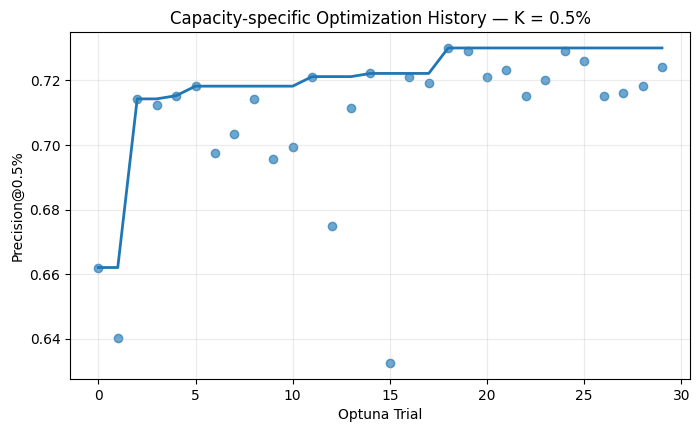

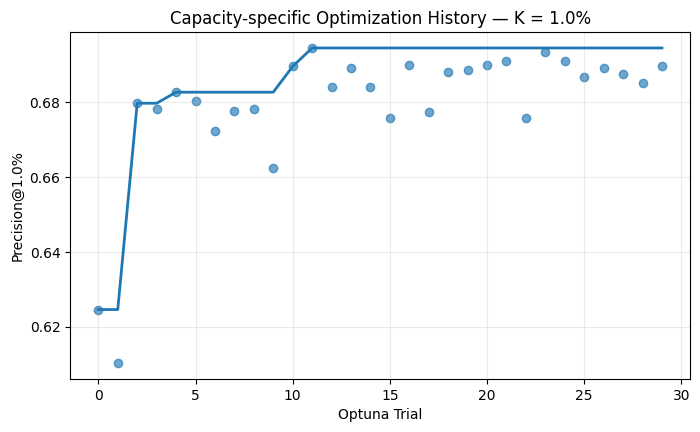

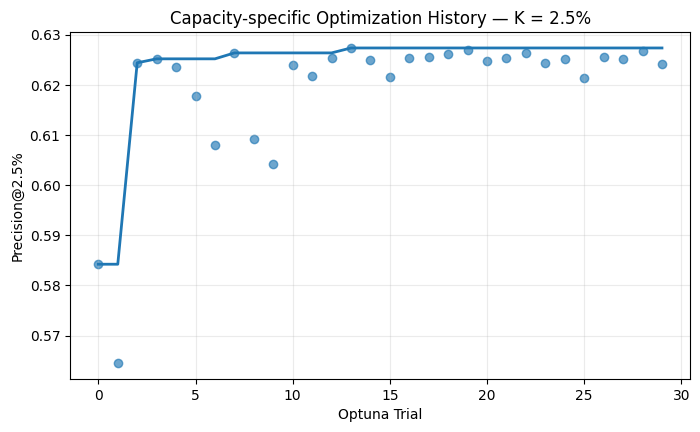

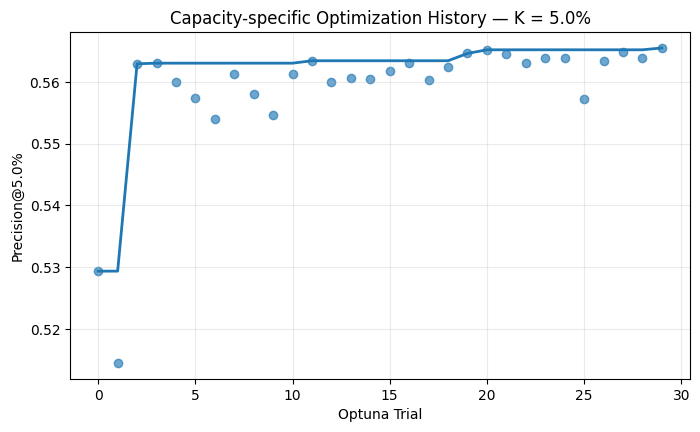

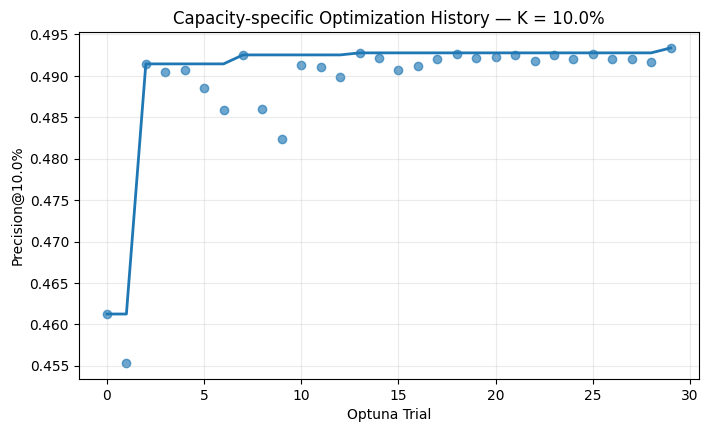

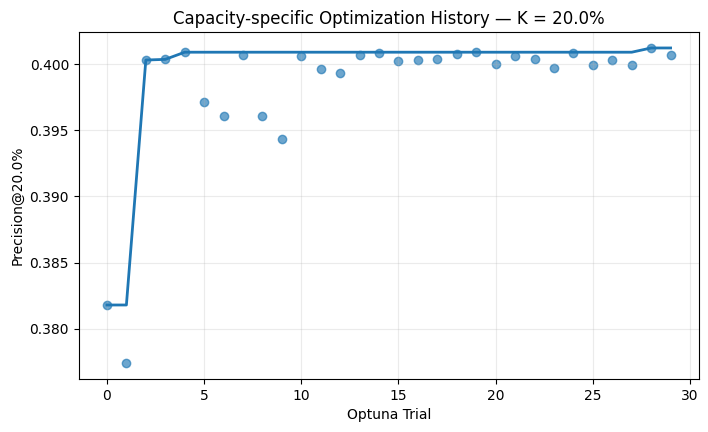

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

capacity_summary = []

for k in CAPACITIES:
    study = capacity_studies[k]

    capacity_summary.append({
        "Capacity": f"{k:.1%}",
        "Best Precision@K": study.best_value,
        "Best Trial": study.best_trial.number,
        "n_estimators": study.best_params["n_estimators"],
        "max_depth": study.best_params["max_depth"],
        "learning_rate": study.best_params["learning_rate"],
        "min_child_weight": study.best_params["min_child_weight"],
        "gamma": study.best_params["gamma"],
        "subsample": study.best_params["subsample"],
        "colsample_bytree": study.best_params["colsample_bytree"],
        "reg_alpha": study.best_params["reg_alpha"],
        "reg_lambda": study.best_params["reg_lambda"],
        "scale_pos_weight": study.best_params["scale_pos_weight"]
    })

capacity_summary_df = pd.DataFrame(capacity_summary)

display(
    capacity_summary_df.style.format({
        "Best Precision@K": "{:.4f}",
        "learning_rate": "{:.4f}",
        "gamma": "{:.4f}",
        "subsample": "{:.4f}",
        "colsample_bytree": "{:.4f}",
        "reg_alpha": "{:.4f}",
        "reg_lambda": "{:.4f}",
        "scale_pos_weight": "{:.4f}"
    })
)

for k in CAPACITIES:
    study = capacity_studies[k]

    trial_numbers = []
    trial_values = []

    for trial in study.trials:
        if trial.value is not None:
            trial_numbers.append(trial.number)
            trial_values.append(trial.value)

    best_so_far = pd.Series(trial_values).cummax()

    plt.figure(figsize=(8, 4.5))
    plt.scatter(trial_numbers, trial_values, alpha=0.65)
    plt.plot(trial_numbers, best_so_far, linewidth=2)

    plt.xlabel("Optuna Trial")
    plt.ylabel(f"Precision@{k:.1%}")
    plt.title(f"Capacity-specific Optimization History — K = {k:.1%}")
    plt.grid(alpha=0.25)
    plt.show()

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

y_test_array = np.asarray(y_test).ravel()

def top_k_metrics(y_true, y_prob, k):
    y_true = np.asarray(y_true).ravel()
    y_prob = np.asarray(y_prob).ravel()

    n = len(y_true)
    n_selected = int(np.ceil(n * k))

    top_idx = np.argsort(y_prob)[::-1][:n_selected]
    y_top = y_true[top_idx]

    precision = y_top.mean()

    total_positive = y_true.sum()
    recall = y_top.sum() / total_positive if total_positive > 0 else np.nan

    prevalence = y_true.mean()
    lift = precision / prevalence if prevalence > 0 else np.nan

    return precision, recall, lift, n_selected


global_test_prob = global_best_model.predict_proba(X_test)[:, 1]

global_test_pr_auc = average_precision_score(
    y_test_array,
    global_test_prob
)

global_test_roc_auc = roc_auc_score(
    y_test_array,
    global_test_prob
)

highest_k_reference = {
    0.01: 0.657,
    0.05: 0.539,
    0.10: 0.472
}

results = []

for k in CAPACITIES:

    global_precision, global_recall, global_lift, n_selected = top_k_metrics(
        y_test_array,
        global_test_prob,
        k
    )

    capacity_prob = capacity_models[k].predict_proba(X_test)[:, 1]

    capacity_precision, capacity_recall, capacity_lift, _ = top_k_metrics(
        y_test_array,
        capacity_prob,
        k
    )

    highest_k = highest_k_reference.get(k, np.nan)

    results.append({
        "Capacity": f"{k:.1%}",
        "Selected Patients": n_selected,

        "Global Precision@K": global_precision,
        "Capacity Precision@K": capacity_precision,
        "Δ Capacity - Global": capacity_precision - global_precision,

        "Global Recall@K": global_recall,
        "Capacity Recall@K": capacity_recall,

        "Global Lift@K": global_lift,
        "Capacity Lift@K": capacity_lift,

        "Highest-k Reference": highest_k,

        "Δ Global - Highest-k":
            global_precision - highest_k
            if not np.isnan(highest_k) else np.nan,

        "Δ Capacity - Highest-k":
            capacity_precision - highest_k
            if not np.isnan(highest_k) else np.nan
    })

final_test_results = pd.DataFrame(results)

print("GLOBAL XGBOOST — LOCKED TEST")
print(f"PR-AUC  : {global_test_pr_auc:.4f}")
print(f"ROC-AUC : {global_test_roc_auc:.4f}")
print(f"Test prevalence: {y_test_array.mean():.4f}")
print()

display(
    final_test_results.style.format({
        "Global Precision@K": "{:.4f}",
        "Capacity Precision@K": "{:.4f}",
        "Δ Capacity - Global": "{:+.4f}",
        "Global Recall@K": "{:.4f}",
        "Capacity Recall@K": "{:.4f}",
        "Global Lift@K": "{:.2f}×",
        "Capacity Lift@K": "{:.2f}×",
        "Highest-k Reference": "{:.4f}",
        "Δ Global - Highest-k": "{:+.4f}",
        "Δ Capacity - Highest-k": "{:+.4f}"
    })
)

GLOBAL XGBOOST — LOCKED TEST
PR-AUC  : 0.4258
ROC-AUC : 0.8280
Test prevalence: 0.1393



,Capacity,Selected Patients,Global Precision@K,Capacity Precision@K,Δ Capacity - Global,Global Recall@K,Capacity Recall@K,Global Lift@K,Capacity Lift@K,Highest-k Reference,Δ Global - Highest-k,Δ Capacity - Highest-k
0,0.5%,254,0.6890,0.6732,-0.0157,0.0248,0.0242,4.94×,4.83×,nan,+nan,+nan
1,1.0%,508,0.6614,0.6614,+0.0000,0.0475,0.0475,4.75×,4.75×,0.6570,+0.0044,+0.0044
2,2.5%,1269,0.6052,0.6028,-0.0024,0.1086,0.1082,4.34×,4.33×,nan,+nan,+nan
3,5.0%,2537,0.5416,0.5388,-0.0028,0.1944,0.1934,3.89×,3.87×,0.5390,+0.0026,-0.0002
4,10.0%,5074,0.4773,0.4781,+0.0008,0.3426,0.3432,3.43×,3.43×,0.4720,+0.0053,+0.0061
5,20.0%,10148,0.3966,0.3963,-0.0003,0.5694,0.5690,2.85×,2.84×,nan,+nan,+nan


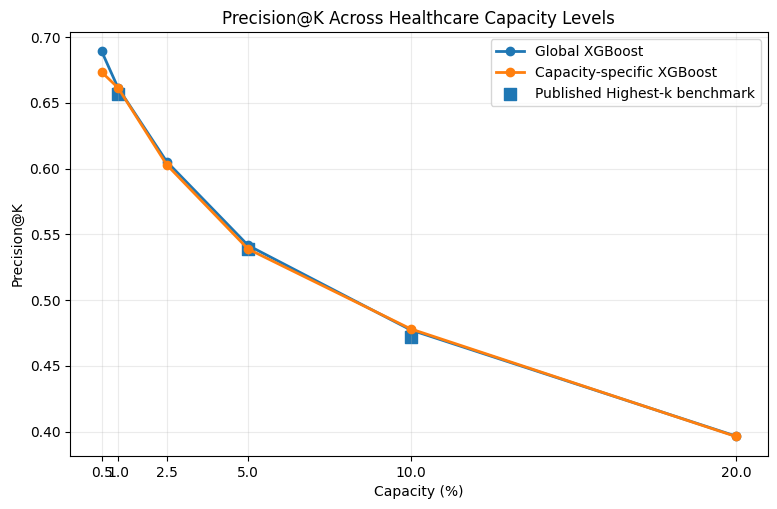

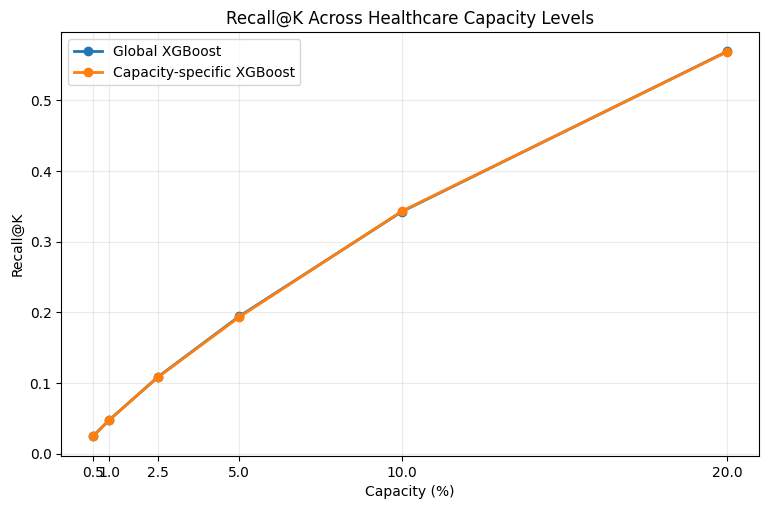

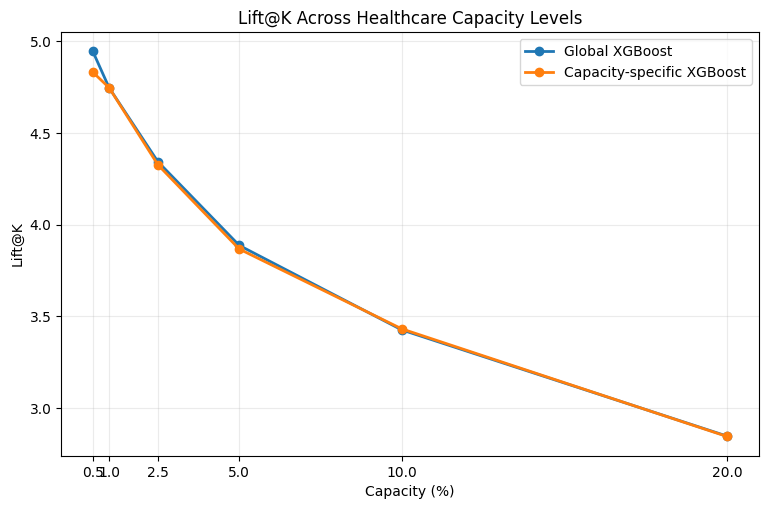

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plot_df = final_test_results.copy()

plot_df["Capacity_num"] = plot_df["Capacity"].str.rstrip("%").astype(float)

plt.figure(figsize=(9, 5.5))
plt.plot(
    plot_df["Capacity_num"],
    plot_df["Global Precision@K"],
    marker="o",
    linewidth=2,
    label="Global XGBoost"
)
plt.plot(
    plot_df["Capacity_num"],
    plot_df["Capacity Precision@K"],
    marker="o",
    linewidth=2,
    label="Capacity-specific XGBoost"
)

highest_k_plot = plot_df.dropna(subset=["Highest-k Reference"])

plt.scatter(
    highest_k_plot["Capacity_num"],
    highest_k_plot["Highest-k Reference"],
    marker="s",
    s=70,
    label="Published Highest-k benchmark"
)

plt.xlabel("Capacity (%)")
plt.ylabel("Precision@K")
plt.title("Precision@K Across Healthcare Capacity Levels")
plt.xticks(plot_df["Capacity_num"])
plt.grid(alpha=0.25)
plt.legend()
plt.show()


plt.figure(figsize=(9, 5.5))
plt.plot(
    plot_df["Capacity_num"],
    plot_df["Global Recall@K"],
    marker="o",
    linewidth=2,
    label="Global XGBoost"
)
plt.plot(
    plot_df["Capacity_num"],
    plot_df["Capacity Recall@K"],
    marker="o",
    linewidth=2,
    label="Capacity-specific XGBoost"
)

plt.xlabel("Capacity (%)")
plt.ylabel("Recall@K")
plt.title("Recall@K Across Healthcare Capacity Levels")
plt.xticks(plot_df["Capacity_num"])
plt.grid(alpha=0.25)
plt.legend()
plt.show()


plt.figure(figsize=(9, 5.5))
plt.plot(
    plot_df["Capacity_num"],
    plot_df["Global Lift@K"],
    marker="o",
    linewidth=2,
    label="Global XGBoost"
)
plt.plot(
    plot_df["Capacity_num"],
    plot_df["Capacity Lift@K"],
    marker="o",
    linewidth=2,
    label="Capacity-specific XGBoost"
)

plt.xlabel("Capacity (%)")
plt.ylabel("Lift@K")
plt.title("Lift@K Across Healthcare Capacity Levels")
plt.xticks(plot_df["Capacity_num"])
plt.grid(alpha=0.25)
plt.legend()
plt.show()

##Feature Importance

,Feature,Importance
0,HighBP,0.4846
1,GenHlth,0.1321
2,HighChol,0.1028
3,HvyAlcoholConsump,0.0403
4,BMI,0.0387
5,Age,0.0365
6,CholCheck,0.0365
7,DiffWalk,0.0284
8,HeartDiseaseorAttack,0.0267
9,Sex,0.0142


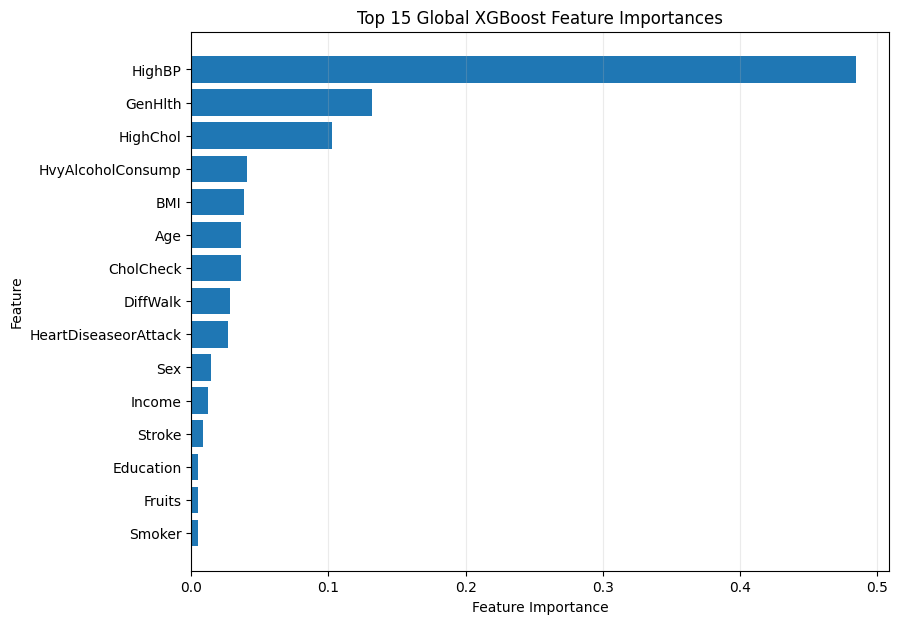

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": global_best_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance)

plt.figure(figsize=(9, 7))

top_features = feature_importance.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Global XGBoost Feature Importances")
plt.grid(axis="x", alpha=0.25)
plt.show()

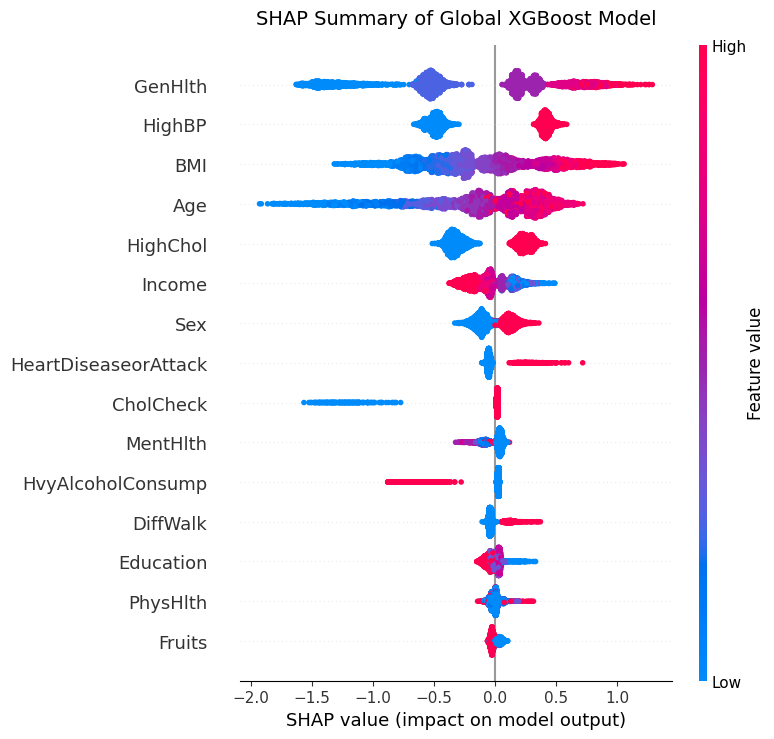

In [ ]:
import shap
import matplotlib.pyplot as plt

X_shap = X_test.sample(
    n=min(5000, len(X_test)),
    random_state=SEED
)

explainer = shap.TreeExplainer(global_best_model)
shap_values = explainer(X_shap)

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values.values,
    X_shap,
    max_display=15,
    show=False
)

plt.title(
    "SHAP Summary of Global XGBoost Model",
    fontsize=14,
    pad=15
)

plt.tight_layout()
plt.show()

Predicted diabetes probability: 0.18903354


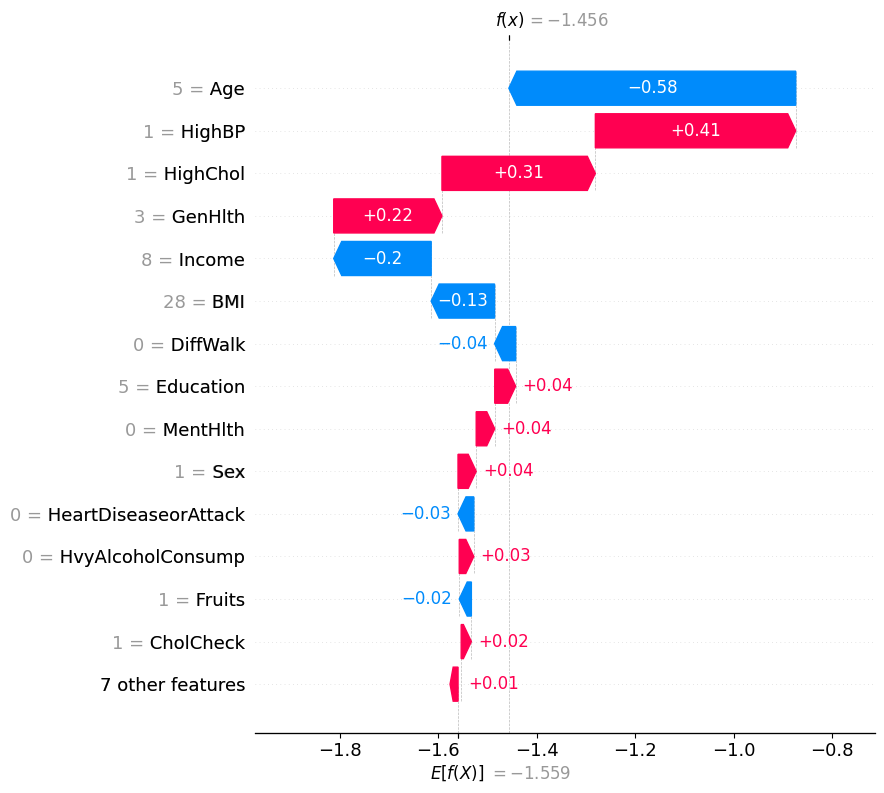

In [ ]:
import shap
import matplotlib.pyplot as plt

patient_idx = 0

patient_data = X_test.iloc[[patient_idx]]

explainer = shap.TreeExplainer(global_best_model)
patient_shap = explainer(patient_data)

print(
    "Predicted diabetes probability:",
    global_best_model.predict_proba(patient_data)[0, 1]
)

shap.plots.waterfall(
    patient_shap[0],
    max_display=15
)

plt.show()

##Brier & Calibration

GLOBAL XGBOOST — CALIBRATION ON LOCKED TEST SET
Test prevalence       : 0.1393 (13.93%)
Brier score           : 0.0987
Naive Brier score     : 0.1199
Brier skill score     : 0.1771



,Mean predicted probability,Observed diabetes rate,Absolute gap
0,0.44%,0.22%,0.23%
1,1.22%,0.99%,0.24%
2,2.52%,2.27%,0.26%
3,4.66%,3.90%,0.76%
4,7.80%,6.03%,1.77%
5,12.39%,9.99%,2.40%
6,18.42%,14.88%,3.54%
7,26.47%,21.72%,4.75%
8,37.44%,31.60%,5.84%
9,56.32%,47.73%,8.59%


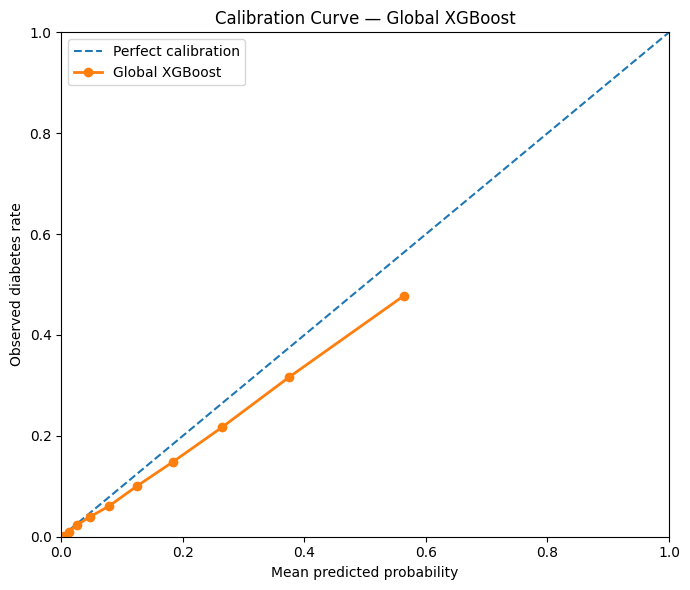

In [ ]:
# ============================================================
# CALIBRATION CHECK — LOCKED TEST SET
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

# ------------------------------------------------------------
# 1. Predictions from final GLOBAL XGBoost
# ------------------------------------------------------------

y_test_cal = np.asarray(y_test).ravel()

global_test_prob_cal = global_best_model.predict_proba(
    X_test
)[:, 1]

# ------------------------------------------------------------
# 2. Brier score
# Lower = better
# 0 = perfect probabilistic prediction
# ------------------------------------------------------------

brier = brier_score_loss(
    y_test_cal,
    global_test_prob_cal
)

prevalence = y_test_cal.mean()

# Naive reference model:
# predict population prevalence for every patient
naive_prob = np.full(
    len(y_test_cal),
    prevalence
)

naive_brier = brier_score_loss(
    y_test_cal,
    naive_prob
)

brier_skill = 1 - (brier / naive_brier)

# ------------------------------------------------------------
# 3. Calibration curve
# Quantile bins are useful because predicted probabilities
# are not uniformly distributed.
# ------------------------------------------------------------

prob_true, prob_pred = calibration_curve(
    y_test_cal,
    global_test_prob_cal,
    n_bins=10,
    strategy="quantile"
)

calibration_table = pd.DataFrame({
    "Mean predicted probability": prob_pred,
    "Observed diabetes rate": prob_true,
    "Absolute gap": np.abs(prob_pred - prob_true)
})

# ------------------------------------------------------------
# 4. Output
# ------------------------------------------------------------

print("=" * 65)
print("GLOBAL XGBOOST — CALIBRATION ON LOCKED TEST SET")
print("=" * 65)

print(f"Test prevalence       : {prevalence:.4f} ({prevalence:.2%})")
print(f"Brier score           : {brier:.4f}")
print(f"Naive Brier score     : {naive_brier:.4f}")
print(f"Brier skill score     : {brier_skill:.4f}")
print()

display(
    calibration_table.style.format({
        "Mean predicted probability": "{:.2%}",
        "Observed diabetes rate": "{:.2%}",
        "Absolute gap": "{:.2%}"
    })
)

# ------------------------------------------------------------
# 5. Calibration plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Perfect calibration"
)

ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    linewidth=2,
    label="Global XGBoost"
)

ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed diabetes rate")
ax.set_title("Calibration Curve — Global XGBoost")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()

plt.tight_layout()
plt.show()

#Reference Research

**Highest-k Loss benchmark from prior research**

Yang et al. (2023) proposed **Highest-k Loss** for disease-risk prediction under limited healthcare resources. Instead of optimizing performance across the entire population, the method directly emphasizes patients receiving the **highest predicted risk scores**, where follow-up capacity is limited.

The study used **253,680 U.S. health survey responses** to construct a diabetes prediction task, matching the same BRFSS-based setting used in this project. Models were evaluated using **Highest-K PPV**, which is equivalent to **Precision@K**, on the highest-risk proportions of the population. The paper used nested cross-validation and an independent external test set.

| Capacity K | Highest-k Loss external Precision@K | Model |
|---:|---:|---|
| **1%** | **0.657** | FCNN |
| **5%** | **0.539** | FCNN |
| **10%** | **0.472** | Logistic / FCNN |

These published values provide an external reference for the **1%, 5%, and 10%** capacity levels in this study. They are not a direct head-to-head comparison because the original paper used its own external test split and training procedure.

**Source:** Yang, H., Gonzalez, R., Nallamothu, B. K., Aaronson, K. D., Ward, K. R., Hero, A. O., & Ansari, S. (2023). *A Practical Approach to Disease Risk Prediction: Focus on High-Risk Patients via Highest-k Loss*. IEEE International Conference on Bioinformatics and Biomedicine, 3226–3233. DOI: 10.1109/BIBM58861.2023.10385816.

#Output for Deployment

In [ ]:
#@title Development Output

import os
import json
import pickle
import platform
import hashlib
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
import xgboost

from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve


# ============================================================
# 1. DEPLOYMENT DIRECTORY
# ============================================================

DEPLOY_DIR = "deployment_bundle"
os.makedirs(DEPLOY_DIR, exist_ok=True)

TARGET = "Diabetes_binary"

FEATURES = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "BMI",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "GenHlth",
    "MentHlth",
    "PhysHlth",
    "DiffWalk",
    "Sex",
    "Age",
    "Education",
    "Income"
]

CAPACITIES = [0.005, 0.01, 0.025, 0.05, 0.10, 0.20]


# ============================================================
# 2. LOAD FINAL GLOBAL MODEL
# ============================================================

model_path = "global_xgboost.pkl"

if os.path.exists(model_path):

    with open(model_path, "rb") as f:
        final_model = pickle.load(f)

    print("Loaded:", model_path)

else:

    candidate_names = [
        "global_best_model",
        "global_model",
        "final_global_model",
        "global_xgb",
        "best_global_model"
    ]

    final_model = None

    for name in candidate_names:

        if name in globals():
            final_model = globals()[name]
            print(f"Using model from variable: {name}")
            break

    if final_model is None:
        raise ValueError(
            "Could not find final global model. "
            "Load global_xgboost.pkl or set final_model manually."
        )


deployment_model_path = os.path.join(
    DEPLOY_DIR,
    "diabetes_global_xgboost.pkl"
)

with open(deployment_model_path, "wb") as f:
    pickle.dump(final_model, f)

print("Saved final model:", deployment_model_path)


# ============================================================
# 3. FEATURE SCHEMA
# ============================================================

feature_schema = {

    "HighBP": {"type": "binary", "min": 0, "max": 1},
    "HighChol": {"type": "binary", "min": 0, "max": 1},
    "CholCheck": {"type": "binary", "min": 0, "max": 1},

    "BMI": {"type": "numeric", "min": 12, "max": 98},

    "Smoker": {"type": "binary", "min": 0, "max": 1},
    "Stroke": {"type": "binary", "min": 0, "max": 1},
    "HeartDiseaseorAttack": {"type": "binary", "min": 0, "max": 1},

    "PhysActivity": {"type": "binary", "min": 0, "max": 1},
    "Fruits": {"type": "binary", "min": 0, "max": 1},
    "Veggies": {"type": "binary", "min": 0, "max": 1},
    "HvyAlcoholConsump": {"type": "binary", "min": 0, "max": 1},

    "AnyHealthcare": {"type": "binary", "min": 0, "max": 1},
    "NoDocbcCost": {"type": "binary", "min": 0, "max": 1},

    "GenHlth": {"type": "ordinal", "min": 1, "max": 5},

    "MentHlth": {"type": "numeric", "min": 0, "max": 30},
    "PhysHlth": {"type": "numeric", "min": 0, "max": 30},

    "DiffWalk": {"type": "binary", "min": 0, "max": 1},
    "Sex": {"type": "binary", "min": 0, "max": 1},

    "Age": {"type": "ordinal", "min": 1, "max": 13},
    "Education": {"type": "ordinal", "min": 1, "max": 6},
    "Income": {"type": "ordinal", "min": 1, "max": 8}
}

schema_output = {
    "target": TARGET,
    "feature_order": FEATURES,
    "n_features": len(FEATURES),
    "features": feature_schema
}

with open(
    os.path.join(DEPLOY_DIR, "feature_schema.json"),
    "w"
) as f:

    json.dump(
        schema_output,
        f,
        indent=2
    )

print("Saved feature_schema.json")


# ============================================================
# 4. FINAL PERFORMANCE + CAPACITY CONFIGURATION
# ============================================================

capacity_results = [

    {
        "capacity": 0.005,
        "capacity_pct": "0.5%",
        "global_precision_at_k": 0.6890,
        "global_recall_at_k": 0.0248,
        "global_lift_at_k": 4.94
    },

    {
        "capacity": 0.01,
        "capacity_pct": "1%",
        "global_precision_at_k": 0.6614,
        "global_recall_at_k": 0.0475,
        "global_lift_at_k": 4.75
    },

    {
        "capacity": 0.025,
        "capacity_pct": "2.5%",
        "global_precision_at_k": 0.6052,
        "global_recall_at_k": 0.1086,
        "global_lift_at_k": 4.34
    },

    {
        "capacity": 0.05,
        "capacity_pct": "5%",
        "global_precision_at_k": 0.5416,
        "global_recall_at_k": 0.1944,
        "global_lift_at_k": 3.89
    },

    {
        "capacity": 0.10,
        "capacity_pct": "10%",
        "global_precision_at_k": 0.4773,
        "global_recall_at_k": 0.3426,
        "global_lift_at_k": 3.43
    },

    {
        "capacity": 0.20,
        "capacity_pct": "20%",
        "global_precision_at_k": 0.3966,
        "global_recall_at_k": 0.5694,
        "global_lift_at_k": 2.85
    }
]

capacity_config = {

    "supported_capacities": CAPACITIES,

    "selection_method":
        "Rank model-estimated risk scores descending and select top K.",

    "locked_test_results": capacity_results
}

with open(
    os.path.join(DEPLOY_DIR, "capacity_config.json"),
    "w"
) as f:

    json.dump(
        capacity_config,
        f,
        indent=2
    )

print("Saved capacity_config.json")


# ============================================================
# 5. CALIBRATION + BRIER SCORE ON LOCKED TEST SET
# ============================================================

if "X_test" not in globals() or "y_test" not in globals():

    raise ValueError(
        "X_test and y_test are required to export "
        "locked-test calibration results."
    )

y_test_cal = np.asarray(y_test).ravel()

global_test_prob_cal = final_model.predict_proba(
    X_test[FEATURES]
)[:, 1]


# ------------------------------------------------------------
# Brier score
# ------------------------------------------------------------

test_prevalence = float(
    y_test_cal.mean()
)

brier = brier_score_loss(
    y_test_cal,
    global_test_prob_cal
)

naive_prob = np.full(
    len(y_test_cal),
    test_prevalence
)

naive_brier = brier_score_loss(
    y_test_cal,
    naive_prob
)

brier_skill = 1 - (
    brier / naive_brier
)


# ------------------------------------------------------------
# Calibration curve
# ------------------------------------------------------------

prob_true, prob_pred = calibration_curve(
    y_test_cal,
    global_test_prob_cal,
    n_bins=10,
    strategy="quantile"
)

calibration_table = pd.DataFrame({

    "mean_predicted_probability": prob_pred,

    "observed_diabetes_rate": prob_true,

    "absolute_gap":
        np.abs(prob_pred - prob_true)
})


# ------------------------------------------------------------
# Save calibration table
# ------------------------------------------------------------

calibration_table.to_csv(
    os.path.join(
        DEPLOY_DIR,
        "calibration_table.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# Save calibration curve
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 6)
)

ax.plot(
    [0, 1],
    [0, 1],
    "--",
    linewidth=1.5,
    label="Perfect calibration"
)

ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    linewidth=2,
    label="Global XGBoost"
)

ax.set_xlabel(
    "Mean predicted probability"
)

ax.set_ylabel(
    "Observed diabetes rate"
)

ax.set_title(
    "Calibration Curve — Global XGBoost"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        DEPLOY_DIR,
        "calibration_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ------------------------------------------------------------
# Save calibration report
# ------------------------------------------------------------

calibration_report = {

    "evaluation_dataset":
        "locked_test_set",

    "n_test":
        int(len(y_test_cal)),

    "diabetes_prevalence":
        test_prevalence,

    "brier_score":
        float(brier),

    "naive_prevalence_brier_score":
        float(naive_brier),

    "brier_skill_score":
        float(brier_skill),

    "calibration_bins":
        10,

    "calibration_strategy":
        "quantile",

    "recalibrated":
        False,

    "interpretation":
        (
            "The model outperforms a prevalence-only probabilistic "
            "baseline but shows increasing overestimation at higher "
            "predicted-risk levels. Outputs should primarily be used "
            "for risk ranking and capacity-based prioritization rather "
            "than interpreted as fully calibrated clinical probabilities."
        ),

    "bin_results": [

        {
            "mean_predicted_probability":
                float(p_pred),

            "observed_diabetes_rate":
                float(p_true),

            "absolute_gap":
                float(abs(p_pred - p_true))
        }

        for p_pred, p_true
        in zip(prob_pred, prob_true)
    ]
}

with open(
    os.path.join(
        DEPLOY_DIR,
        "calibration_report.json"
    ),
    "w"
) as f:

    json.dump(
        calibration_report,
        f,
        indent=2
    )

print("Saved calibration_table.csv")
print("Saved calibration_curve.png")
print("Saved calibration_report.json")

print(
    f"Calibration: Brier={brier:.4f}, "
    f"Naive={naive_brier:.4f}, "
    f"Skill={brier_skill:.4f}"
)


# ============================================================
# 6. RISK OUTPUT POLICY
# ============================================================

risk_output_policy = {

    "primary_display_name":
        "Model-estimated diabetes risk score",

    "primary_use":
        "Risk ranking and capacity-based patient prioritization",

    "probability_warning":
        (
            "The score is produced by predict_proba but the model "
            "shows some overestimation at higher risk levels. "
            "It should not be interpreted as a fully calibrated "
            "clinical probability."
        ),

    "capacity_rule":
        (
            "Do not use a fixed 0.50 threshold. "
            "Rank patients by risk score and select the top K "
            "according to available healthcare capacity."
        ),

    "clinical_disclaimer":
        (
            "This tool supports diabetes screening and prioritization "
            "and does not provide a clinical diagnosis."
        )
}

with open(
    os.path.join(
        DEPLOY_DIR,
        "risk_output_policy.json"
    ),
    "w"
) as f:

    json.dump(
        risk_output_policy,
        f,
        indent=2
    )

print("Saved risk_output_policy.json")


# ============================================================
# 7. MODEL METADATA
# ============================================================

metadata = {

    "model_name":
        "BRFSS 2015 Diabetes Global XGBoost",

    "model_version":
        "1.0.0",

    "created_at":
        datetime.now(timezone.utc).isoformat(),

    "dataset":
        "CDC Diabetes Health Indicators derived from BRFSS 2015",

    "target":
        TARGET,

    "n_features":
        len(FEATURES),

    "training_objective":
        "Global PR-AUC optimization",

    "hyperparameter_optimizer":
        "Optuna",

    "cross_validation":
        "5-fold Stratified K-Fold",

    "train_test_split":
        "80/20 stratified, locked test",

    "oof_pr_auc":
        0.4384,

    "oof_roc_auc":
        0.8316,

    "calibration": {

        "checked":
            True,

        "evaluation_dataset":
            "locked_test_set",

        "brier_score":
            float(brier),

        "naive_brier_score":
            float(naive_brier),

        "brier_skill_score":
            float(brier_skill),

        "n_bins":
            10,

        "strategy":
            "quantile",

        "recalibrated":
            False,

        "deployment_interpretation":
            "Use as model-estimated risk score primarily for ranking."
    },

    "intended_use":
        "Diabetes risk screening and capacity-based patient prioritization",

    "not_intended_for": [
        "Clinical diagnosis",
        "Causal inference",
        "Fully calibrated individual probability estimation"
    ],

    "retraining_policy": {

        "frequency_days":
            30,

        "condition":
            (
                "Retrain only when sufficient new labeled "
                "outcomes are available."
            )
    },

    "python_version":
        platform.python_version(),

    "pandas_version":
        pd.__version__,

    "numpy_version":
        np.__version__,

    "sklearn_version":
        sklearn.__version__,

    "xgboost_version":
        xgboost.__version__
}

with open(
    os.path.join(
        DEPLOY_DIR,
        "model_metadata.json"
    ),
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=2
    )

print("Saved model_metadata.json")


# ============================================================
# 8. SHAP BACKGROUND / REFERENCE DATA
# ============================================================

if "X_train" in globals():

    X_reference = X_train[FEATURES].copy()

elif "X_train_full" in globals():

    X_reference = X_train_full[FEATURES].copy()

elif "df" in globals():

    X_reference = df[FEATURES].copy()

else:

    raise ValueError(
        "Need X_train, X_train_full, or df "
        "to generate deployment reference data."
    )


shap_background = X_reference.sample(
    n=min(500, len(X_reference)),
    random_state=42
)

shap_background.to_csv(
    os.path.join(
        DEPLOY_DIR,
        "shap_background.csv"
    ),
    index=False
)

print("Saved shap_background.csv")


# ============================================================
# 9. REFERENCE RISK DISTRIBUTION
# ============================================================

reference_probs = final_model.predict_proba(
    X_reference[FEATURES]
)[:, 1]

risk_percentiles = {

    "p50":
        float(np.percentile(reference_probs, 50)),

    "p75":
        float(np.percentile(reference_probs, 75)),

    "p90":
        float(np.percentile(reference_probs, 90)),

    "p95":
        float(np.percentile(reference_probs, 95)),

    "p97_5":
        float(np.percentile(reference_probs, 97.5)),

    "p99":
        float(np.percentile(reference_probs, 99)),

    "p99_5":
        float(np.percentile(reference_probs, 99.5)),

    "max":
        float(reference_probs.max())
}

with open(
    os.path.join(
        DEPLOY_DIR,
        "risk_reference.json"
    ),
    "w"
) as f:

    json.dump(
        risk_percentiles,
        f,
        indent=2
    )

print("Saved risk_reference.json")


# ============================================================
# 10. SAMPLE INPUT + SAMPLE OUTPUT
# ============================================================

sample_input = (
    X_reference[FEATURES]
    .iloc[[0]]
    .copy()
)

sample_input.to_csv(
    os.path.join(
        DEPLOY_DIR,
        "sample_input.csv"
    ),
    index=False
)

sample_risk = float(
    final_model.predict_proba(
        sample_input
    )[0, 1]
)


# percentile relative to reference population
risk_percentile = float(
    (
        reference_probs
        <= sample_risk
    ).mean()
)


sample_output = {

    # backward-compatible raw model output
    "raw_predict_proba":
        sample_risk,

    # preferred deployment wording
    "model_estimated_risk_score":
        sample_risk,

    "model_estimated_risk_score_pct":
        round(
            sample_risk * 100,
            2
        ),

    "risk_percentile":
        risk_percentile,

    "risk_percentile_pct":
        round(
            risk_percentile * 100,
            2
        ),

    "calibrated_probability":
        None,

    "calibration_status":
        "evaluated_but_not_recalibrated",

    "interpretation":
        (
            "Use primarily for ranking and capacity-based prioritization."
        )
}

with open(
    os.path.join(
        DEPLOY_DIR,
        "sample_output.json"
    ),
    "w"
) as f:

    json.dump(
        sample_output,
        f,
        indent=2
    )

print("Saved sample_input.csv")
print("Saved sample_output.json")


# ============================================================
# 11. LOGGING SCHEMA FOR GOOGLE SHEETS / DATABASE
# ============================================================

logging_columns = [

    "prediction_id",
    "timestamp",
    "model_version",

    *FEATURES,

    "model_estimated_risk_score",
    "risk_percentile",

    "top_feature_1",
    "top_feature_1_shap",

    "top_feature_2",
    "top_feature_2_shap",

    "top_feature_3",
    "top_feature_3_shap",

    # populated later when actual outcome becomes known
    "actual_diabetes_outcome",
    "outcome_recorded_at"
]

logging_schema = pd.DataFrame({
    "column": logging_columns
})

logging_schema.to_csv(
    os.path.join(
        DEPLOY_DIR,
        "prediction_logging_schema.csv"
    ),
    index=False
)

print("Saved prediction_logging_schema.csv")


# ============================================================
# 12. RETRAINING CONFIG
# ============================================================

retraining_config = {

    "schedule_days":
        30,

    "minimum_requirements": [

        "New records must contain all 21 required features",

        "Actual diabetes outcome must be available",

        "Input ranges must pass validation"
    ],

    "steps": [

        "Load historical and newly labeled data",

        "Validate schema and feature ranges",

        "Create stratified training and validation procedure",

        "Retrain XGBoost pipeline",

        "Evaluate PR-AUC",

        "Evaluate Precision@K, Recall@K, and Lift@K",

        "Evaluate Brier score and calibration curve",

        "Compare candidate model with current production model",

        "Replace production model only if predefined validation criteria are satisfied",

        "Increment model version"
    ],

    "primary_ranking_metric":
        "PR-AUC",

    "capacity_metrics": [
        "Precision@K",
        "Recall@K",
        "Lift@K"
    ],

    "probability_quality_metrics": [
        "Brier score",
        "Calibration curve"
    ]
}

with open(
    os.path.join(
        DEPLOY_DIR,
        "retraining_config.json"
    ),
    "w"
) as f:

    json.dump(
        retraining_config,
        f,
        indent=2
    )

print("Saved retraining_config.json")


# ============================================================
# 13. MODEL FILE CHECKSUM
# ============================================================

with open(
    deployment_model_path,
    "rb"
) as f:

    model_hash = hashlib.sha256(
        f.read()
    ).hexdigest()

with open(
    os.path.join(
        DEPLOY_DIR,
        "model_checksum.txt"
    ),
    "w"
) as f:

    f.write(model_hash)

print("Saved model_checksum.txt")


# ============================================================
# 14. FINAL DEPLOYMENT VALIDATION
# ============================================================

with open(
    deployment_model_path,
    "rb"
) as f:

    loaded_model = pickle.load(f)

test_prob = loaded_model.predict_proba(
    sample_input[FEATURES]
)[0, 1]


assert np.isclose(
    test_prob,
    sample_risk
), "Deployment model prediction mismatch!"


assert (
    list(sample_input.columns)
    == FEATURES
), "Feature order mismatch!"


required_files = [

    "diabetes_global_xgboost.pkl",

    "feature_schema.json",

    "capacity_config.json",

    "model_metadata.json",

    "risk_output_policy.json",

    "shap_background.csv",

    "risk_reference.json",

    "sample_input.csv",

    "sample_output.json",

    "prediction_logging_schema.csv",

    "retraining_config.json",

    "model_checksum.txt",

    "calibration_report.json",

    "calibration_table.csv",

    "calibration_curve.png"
]


missing_files = [

    file
    for file in required_files

    if not os.path.exists(
        os.path.join(
            DEPLOY_DIR,
            file
        )
    )
]

assert not missing_files, (
    f"Missing deployment files: {missing_files}"
)


print("\n" + "=" * 70)
print("DEPLOYMENT VALIDATION PASSED")
print("=" * 70)

print(
    f"Number of features       : {len(FEATURES)}"
)

print(
    f"Sample raw risk score    : {test_prob:.6f}"
)

print(
    f"Sample risk score (%)    : {test_prob * 100:.2f}%"
)

print(
    f"Sample risk percentile   : {risk_percentile * 100:.2f}%"
)

print()
print("Calibration:")
print(
    f"  Brier score            : {brier:.4f}"
)

print(
    f"  Naive Brier score      : {naive_brier:.4f}"
)

print(
    f"  Brier skill score      : {brier_skill:.4f}"
)

print()
print("Interpretation:")
print(
    "  Risk score is intended primarily for ranking and "
    "capacity-based prioritization."
)

print(
    "  It is NOT exported as a fully calibrated clinical probability."
)

print("\nFiles generated:")

for file in sorted(
    os.listdir(DEPLOY_DIR)
):
    print(" -", file)

Loaded: global_xgboost.pkl
Saved final model: deployment_bundle/diabetes_global_xgboost.pkl
Saved feature_schema.json
Saved capacity_config.json
Saved calibration_table.csv
Saved calibration_curve.png
Saved calibration_report.json
Calibration: Brier=0.0987, Naive=0.1199, Skill=0.1771
Saved risk_output_policy.json
Saved model_metadata.json
Saved shap_background.csv
Saved risk_reference.json
Saved sample_input.csv
Saved sample_output.json
Saved prediction_logging_schema.csv
Saved retraining_config.json
Saved model_checksum.txt

DEPLOYMENT VALIDATION PASSED
Number of features       : 21
Sample raw risk score    : 0.010257
Sample risk score (%)    : 1.03%
Sample risk percentile   : 12.84%

Calibration:
  Brier score            : 0.0987
  Naive Brier score      : 0.1199
  Brier skill score      : 0.1771

Interpretation:
  Risk score is intended primarily for ranking and capacity-based prioritization.
  It is NOT exported as a fully calibrated clinical probability.

Files generated:
 - calib

In [ ]:
from google.colab import drive
import shutil
import os
from datetime import datetime

# Mount Google Drive
drive.mount("/content/drive")

# Folder deployment đã tạo
SOURCE_FOLDER = "/content/deployment_bundle"

# Đúng folder trong ảnh:
# My Drive > Data Mining > prj nhóm
DRIVE_FOLDER = "/content/drive/MyDrive/Data Mining/prj nhóm"

os.makedirs(DRIVE_FOLDER, exist_ok=True)

# Tạo version theo thời gian
timestamp = datetime.now().strftime("%Y%m%d_%H%M")
zip_name = f"diabetes_deployment_bundle_{timestamp}"

zip_base_path = os.path.join(DRIVE_FOLDER, zip_name)

# Zip và lưu trực tiếp vào Drive
zip_path = shutil.make_archive(
    zip_base_path,
    "zip",
    root_dir=SOURCE_FOLDER
)

print("=" * 65)
print("DEPLOYMENT BUNDLE SAVED SUCCESSFULLY")
print("=" * 65)
print(f"Drive folder : {DRIVE_FOLDER}")
print(f"ZIP file     : {zip_path}")
print(f"ZIP size     : {os.path.getsize(zip_path)/(1024**2):.2f} MB")

print("\nFiles included:")
for file in sorted(os.listdir(SOURCE_FOLDER)):
    print(" -", file)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DEPLOYMENT BUNDLE SAVED SUCCESSFULLY
Drive folder : /content/drive/MyDrive/Data Mining/prj nhóm
ZIP file     : /content/drive/MyDrive/Data Mining/prj nhóm/diabetes_deployment_bundle_20261022_0624.zip
ZIP size     : 0.53 MB

Files included:
 - capacity_config.json
 - diabetes_global_xgboost.pkl
 - feature_schema.json
 - model_checksum.txt
 - model_metadata.json
 - prediction_logging_schema.csv
 - retraining_config.json
 - risk_reference.json
 - sample_input.csv
 - sample_output.json
 - shap_background.csv
